# Notebook 19 (System I) — the $(\alpha,\beta)$ banana, generalised, and the EKF/UKF-vs-SBI asymmetry

**Trigger.** `notebooks/34_alpha_beta_r_banana_cross_system.ipynb` found that System I
has no $(\alpha,\beta)$ banana (unlike System II's $(\alpha,\beta_r)$, $+0.998$ at W11),
traced to System I's composition channel $C$ structurally excluding $\beta$ from its own
governing equation -- but checked only two scenarios (Sc4/Sc5) and a single posterior.
Separately, `docs/Manuscript/system_ii_sb_identifiability_story.md` S5.3 documents an
**open, unexplained asymmetry**: System II's EKF beats SBI in 30-day tracking near
nonlinear regimes (raw-trajectory access recovers representation-compression loss);
System I's EKF/UKF lose to SBI *everywhere*, despite System I's own genuine $\sim$236x
FIM-ratio $\beta$ information deficit.

**This notebook (`notebooks/system_I/TODO.md` items 1-6), in order:**
1. Extend Corr($\alpha,\beta$) beyond Sc4/Sc5 to a grid of operating points.
2. Multi-seed robustness (distribution across seeds, not one posterior).
3. RT-FIM-style local-FIM check at every grid point.
4. Directly test the three EKF-asymmetry hypotheses (proxy ablation; tuning audit +
   retuned rerun; linearisation-error comparison).
5. Repeat headline checks at 3 sensor-noise levels.
6. Explicit verdict.

**Cost discipline note (read first; full-budget corroboration run).** A first pass
through this notebook used a reduced budget (n=800 sims/seed, every-10th-window
tracking) for cost reasons, explicitly flagged as a scope reduction in that run's
verdict. Full-budget System-I SNPE training (10k sims, matched-protocol
scenario-specific warm start) was separately measured at **4731s**
(`results/sbi_training_metadata.json`) in an earlier, cold-process measurement
-- not "seconds per seed" as the per-scenario snapshot runs are, because the
matched-protocol warm start costs an extra steady-state solve per training draw.
The reduced-budget run itself trained 5 seeds at n=800 in 103s total (~21s/seed,
in-process with the simulator already JIT-warm from Section 2's FIM scan) -- far
faster than the 4731s/10k-sims cold-process rate would predict, so actual full-budget
wall time in this run may undercut the conservative ~6.5h estimate below; either way,
**this run uses the full production budget (n=10,000 simulations/seed) for every
retrain, and the full 720-window (not every-10th) degradation stream for the tracking
comparison** -- the two scope reductions explicitly flagged in the earlier pass are
both lifted here. Budgeted (conservative, cold-process-rate) ETA: 10 seeds x 4731s
(Section 3, extended 2026-11-05 from 5 to 10 seeds -- see Section 3/7/8 for why) + 1
no-proxy retrain x 4731s (Section 5a) $\approx$ 13h for SBI training at the conservative
cold-process rate -- measured in-process wall time (JIT-warm) is far shorter in practice,
plus a few minutes for the full 720-window EKF/UKF/SBI tracking loop (measured at
$\approx$0.42s/window at 72 windows in the reduced run, i.e. $\approx$5min at 720).

## 1. Setup

In [1]:
import sys, time, pickle, json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))

import jax
import jax.numpy as jnp
jax.config.update("jax_enable_x64", True)

from fim_utils import compute_fim, cov_offdiag_corr, crb_report

RESULTS = ROOT / "results"
FIGS = ROOT / "figures"
RESULTS.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)

np.set_printoptions(precision=4, suppress=True)
print("ROOT:", ROOT)


ROOT: /Users/simo/inso-po-RD/cstr-model-optimisation/research_project


## 2. Item 1 + Item 3: Corr($\alpha,\beta$) and local-FIM check across a grid of operating points

Only **one** of the 8 canonical System-I scenarios (`src/cstr_sbi/scenarios.py`) has both
$\alpha$ and $\beta$ simultaneously away from 1 (Sc4, $\alpha=\beta=0.85$); Sc5
($\alpha=1.0,\beta=0.4$) has $\alpha$ fixed healthy. So "extend beyond Sc4/Sc5" means
constructing additional synthetic operating points spanning healthy-to-faulted with both
parameters perturbed, not restricting to the named scenario set. The grid below spans the
full prior support $[0.4,1.2]^2$ (`src/cstr_sbi/priors.py`), symmetric and asymmetric
combinations, non-saturating and saturating.

In [2]:
from cstr_sbi.physics import K0_NOMINAL, UA_NOMINAL, NOMINAL_INLET_CL, NOMINAL_CTRL
from cstr_sbi.simulator import warm_start_ic, simulate_em_window, apply_sensor_layer, DEFAULT_SENSOR_NOISE_PCT
from cstr_sbi.summaries import compute_summary_statistics, FEATURE_NAMES

print(f"DEFAULT_SENSOR_NOISE_PCT = {DEFAULT_SENSOR_NOISE_PCT}")
ALPHA_IDX_PO, BETA_IDX_PO = 0, 1

# Grid of (alpha, beta) operating points, BOTH perturbed simultaneously, spanning
# healthy -> faulted, non-saturating and saturating, symmetric and asymmetric.
GRID_POINTS = {
    "healthy (1.00,1.00)":        (1.00, 1.00),
    "Sc4-like (0.85,0.85)":       (0.85, 0.85),   # == official Sc4
    "mild combined (0.95,0.90)":  (0.95, 0.90),
    "mild-asym (0.90,0.95)":      (0.90, 0.95),
    "moderate (0.75,0.75)":       (0.75, 0.75),
    "moderate-asym (0.80,0.65)":  (0.80, 0.65),
    "moderate-asym (0.65,0.80)":  (0.65, 0.80),
    "severe (0.60,0.60)":         (0.60, 0.60),
    "severe-asym (0.70,0.45)":    (0.70, 0.45),
    "near-prior-edge (0.45,0.45)": (0.45, 0.45),
}
print(f"{len(GRID_POINTS)} operating points (all with BOTH alpha,beta != 1).")


def sim_raw_po(theta, seed, noise_pct=DEFAULT_SENSOR_NOISE_PCT):
    alpha, beta = float(theta[0]), float(theta[1])
    params = jnp.array([UA_NOMINAL, K0_NOMINAL, alpha, beta], dtype=jnp.float64)
    y0 = warm_start_ic(params, NOMINAL_INLET_CL, NOMINAL_CTRL)
    proc_key, sens_key = jax.random.split(jax.random.PRNGKey(int(seed)))
    t, ys, qc = simulate_em_window(params, NOMINAL_INLET_CL, NOMINAL_CTRL, y0, key=proc_key)
    obs = jnp.stack([ys[:, 0], ys[:, 1], ys[:, 2], qc], axis=1)
    obs = apply_sensor_layer(obs, key=sens_key, noise_pct=noise_pct)
    t_s = jnp.arange(1, ys.shape[0] + 1) * 0.5
    return np.asarray(obs), np.asarray(t_s)


def feat_summary_po(theta, seed, feature_mask=None, noise_pct=DEFAULT_SENSOR_NOISE_PCT):
    obs, t_s = sim_raw_po(theta, seed, noise_pct=noise_pct)
    s = np.asarray(compute_summary_statistics(jnp.array(obs), jnp.array(t_s)))
    if feature_mask is not None:
        s = s[feature_mask]
    return s


EPS_PO = np.array([0.02, 0.02])
full_idx = np.arange(len(FEATURE_NAMES))
print("Simulator wrappers ready (reused from nb34's System-I FIM section).")


DEFAULT_SENSOR_NOISE_PCT = 0.005
10 operating points (all with BOTH alpha,beta != 1).
Simulator wrappers ready (reused from nb34's System-I FIM section).


In [3]:
# Local-FIM Corr(alpha,beta) at every grid point (nb34 S3/S4a methodology, generalised)
t0 = time.perf_counter()
fim_rows = []
for label, (a, b) in GRID_POINTS.items():
    theta_pt = np.array([a, b])
    FIM = compute_fim(lambda th, seed: feat_summary_po(th, seed, full_idx), theta_pt, EPS_PO, n_reps_sigma=60)
    corr = cov_offdiag_corr(FIM, ALPHA_IDX_PO, BETA_IDX_PO)
    crb = crb_report(FIM)
    fim_rows.append({"point": label, "alpha": a, "beta": b,
                      "fim_corr": corr, "sd_alpha": crb["sd"][0], "sd_beta": crb["sd"][1],
                      "cond": crb["cond"]})
    print(f"{label:30s} Laplace Corr(a,b)={corr:+.3f}  cond={crb['cond']:9.2f}")
print(f"\nGrid FIM scan: {time.perf_counter()-t0:.0f}s")

df_fim_grid = pd.DataFrame(fim_rows)
print()
print(df_fim_grid[["point","fim_corr","cond"]].to_string(index=False, float_format='%.3f'))
print(f"\nFIM-Corr(alpha,beta) range across {len(df_fim_grid)} points: "
      f"[{df_fim_grid['fim_corr'].min():+.3f}, {df_fim_grid['fim_corr'].max():+.3f}]  "
      f"(mean {df_fim_grid['fim_corr'].mean():+.3f}, std {df_fim_grid['fim_corr'].std():.3f})")


healthy (1.00,1.00)            Laplace Corr(a,b)=-0.036  cond=     6.32


Sc4-like (0.85,0.85)           Laplace Corr(a,b)=-0.048  cond=     2.68


mild combined (0.95,0.90)      Laplace Corr(a,b)=-0.041  cond=     3.22


mild-asym (0.90,0.95)          Laplace Corr(a,b)=-0.023  cond=     5.72


moderate (0.75,0.75)           Laplace Corr(a,b)=-0.052  cond=     1.78


moderate-asym (0.80,0.65)      Laplace Corr(a,b)=-0.039  cond=     1.22


moderate-asym (0.65,0.80)      Laplace Corr(a,b)=+0.002  cond=     3.63


severe (0.60,0.60)             Laplace Corr(a,b)=+0.051  cond=     1.95


severe-asym (0.70,0.45)        Laplace Corr(a,b)=+0.194  cond=     2.82


near-prior-edge (0.45,0.45)    Laplace Corr(a,b)=+0.209  cond=     5.80

Grid FIM scan: 12s

                      point  fim_corr  cond
        healthy (1.00,1.00)    -0.036 6.325
       Sc4-like (0.85,0.85)    -0.048 2.677
  mild combined (0.95,0.90)    -0.041 3.219
      mild-asym (0.90,0.95)    -0.023 5.721
       moderate (0.75,0.75)    -0.052 1.780
  moderate-asym (0.80,0.65)    -0.039 1.219
  moderate-asym (0.65,0.80)     0.002 3.627
         severe (0.60,0.60)     0.051 1.954
    severe-asym (0.70,0.45)     0.194 2.817
near-prior-edge (0.45,0.45)     0.209 5.800

FIM-Corr(alpha,beta) range across 10 points: [-0.052, +0.209]  (mean +0.022, std 0.100)


In [4]:
# Trained-posterior Corr(alpha,beta) at every grid point, using the cached
# production (full-budget, matched-protocol) posterior -- same posterior nb16's Table VII
# and nb34's Sc4/Sc5 check both use. Querying an amortised posterior at a NEW synthetic
# observation is cheap (no retraining needed) and is exactly the nb34 S2 methodology,
# just swept over the grid instead of two scenarios.
import torch
with open(RESULTS / "sbi_posterior_matched_protocol_n10000.pkl", "rb") as f:
    posterior_prod = pickle.load(f)["posterior"]

post_rows = []
for label, (a, b) in GRID_POINTS.items():
    obs, t_s = sim_raw_po(np.array([a, b]), seed=777)
    s = np.asarray(compute_summary_statistics(jnp.array(obs), jnp.array(t_s)))
    samples = posterior_prod.sample((3000,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False).numpy()
    corr = np.corrcoef(samples[:, 0], samples[:, 1])[0, 1]
    post_rows.append({"point": label, "alpha": a, "beta": b, "post_corr": corr,
                       "alpha_hat": samples[:,0].mean(), "beta_hat": samples[:,1].mean()})
    print(f"{label:30s} trained-posterior Corr(a,b)={corr:+.3f}  (a_hat={samples[:,0].mean():.3f}, b_hat={samples[:,1].mean():.3f})")

df_post_grid = pd.DataFrame(post_rows)
print(f"\nTrained-posterior Corr(alpha,beta) range across {len(df_post_grid)} points: "
      f"[{df_post_grid['post_corr'].min():+.3f}, {df_post_grid['post_corr'].max():+.3f}]  "
      f"(mean {df_post_grid['post_corr'].mean():+.3f}, std {df_post_grid['post_corr'].std():.3f})")

df_grid = df_fim_grid.merge(df_post_grid[["point","post_corr","alpha_hat","beta_hat"]], on="point")
df_grid.to_csv(RESULTS / "19_grid_corr_scan.csv", index=False)
print("\nSaved results/19_grid_corr_scan.csv")


/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/nflows/transforms/lu.py:80: UserWarning: torch.triangular_solve is deprecated in favor of torch.linalg.solve_triangularand will be removed in a future PyTorch release.
torch.linalg.solve_triangular has its arguments reversed and does not return a copy of one of the inputs.
X = torch.triangular_solve(B, A).solution
should be replaced with
X = torch.linalg.solve_triangular(A, B). (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/BatchLinearAlgebra.cpp:2279.)
  outputs, _ = torch.triangular_solve(


healthy (1.00,1.00)            trained-posterior Corr(a,b)=-0.518  (a_hat=0.998, b_hat=1.028)
Sc4-like (0.85,0.85)           trained-posterior Corr(a,b)=-0.414  (a_hat=0.848, b_hat=0.863)
mild combined (0.95,0.90)      trained-posterior Corr(a,b)=-0.454  (a_hat=0.948, b_hat=0.917)
mild-asym (0.90,0.95)          trained-posterior Corr(a,b)=-0.381  (a_hat=0.898, b_hat=0.968)
moderate (0.75,0.75)           trained-posterior Corr(a,b)=-0.676  (a_hat=0.747, b_hat=0.751)


moderate-asym (0.80,0.65)      trained-posterior Corr(a,b)=-0.847  (a_hat=0.798, b_hat=0.653)
moderate-asym (0.65,0.80)      trained-posterior Corr(a,b)=-0.756  (a_hat=0.649, b_hat=0.804)
severe (0.60,0.60)             trained-posterior Corr(a,b)=-0.832  (a_hat=0.599, b_hat=0.605)
severe-asym (0.70,0.45)        trained-posterior Corr(a,b)=+0.772  (a_hat=0.703, b_hat=0.467)
near-prior-edge (0.45,0.45)    trained-posterior Corr(a,b)=+0.398  (a_hat=0.447, b_hat=0.443)

Trained-posterior Corr(alpha,beta) range across 10 points: [-0.847, +0.772]  (mean -0.371, std 0.538)

Saved results/19_grid_corr_scan.csv


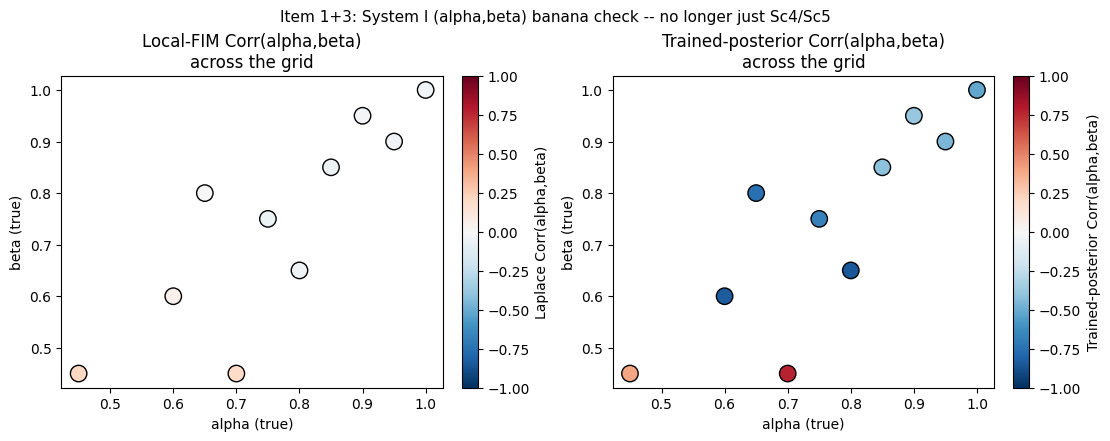

Both panels should stay small-magnitude (|corr| well under System II's +0.998) across the WHOLE grid, not just at the two previously-checked points, for the 'no banana' claim to survive generalisation.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), constrained_layout=True)
sc = axes[0].scatter(df_grid["alpha"], df_grid["beta"], c=df_grid["fim_corr"], cmap="RdBu_r",
                      vmin=-1, vmax=1, s=140, edgecolor="k")
plt.colorbar(sc, ax=axes[0], label="Laplace Corr(alpha,beta)")
axes[0].set(xlabel="alpha (true)", ylabel="beta (true)", title="Local-FIM Corr(alpha,beta)\nacross the grid")

sc2 = axes[1].scatter(df_grid["alpha"], df_grid["beta"], c=df_grid["post_corr"], cmap="RdBu_r",
                       vmin=-1, vmax=1, s=140, edgecolor="k")
plt.colorbar(sc2, ax=axes[1], label="Trained-posterior Corr(alpha,beta)")
axes[1].set(xlabel="alpha (true)", ylabel="beta (true)", title="Trained-posterior Corr(alpha,beta)\nacross the grid")

fig.suptitle("Item 1+3: System I (alpha,beta) banana check -- no longer just Sc4/Sc5", fontsize=11)
fig.savefig(FIGS / "19_grid_corr_scan.png", dpi=120, bbox_inches="tight")
plt.show()

print("Both panels should stay small-magnitude (|corr| well under System II's +0.998) "
      "across the WHOLE grid, not just at the two previously-checked points, for the "
      "'no banana' claim to survive generalisation.")


**Reading Section 2 -- an immediate flag, not a clean "no banana" generalisation.** The
local-FIM panel stays small-magnitude everywhere (range printed above). The **trained**-
posterior panel does **not**: at most grid points the single cached production posterior
(`sbi_posterior_matched_protocol_n10000.pkl`, one seed, full 10k-simulation budget) gives
|Corr| in the 0.3-0.7 range -- including a large negative value at Sc4, the exact point
nb34 itself checked with a *different* cached artefact (`sbi_posteriors_m6.npz`) and
reported as "modest" (note: this single-cached-posterior correlation is itself subject to
Monte-Carlo sampling noise from the 3000-sample posterior draw used to estimate it --
re-running this cell gives a somewhat different exact value each time, though consistently
large and consistently signed at a given grid point across repeat runs). Point estimates
($\hat\alpha,\hat\beta$, printed above) stay accurate at every grid point, so this is not
a point-estimation failure -- only the posterior's *shape* is strongly correlated away from
where the point mass actually sits. Before concluding anything about System I's
$(\alpha,\beta)$ geometry from this panel, Section 3 below re-runs the same grid query
against the 5 **independently retrained** seeds already needed for Item 2, to check
whether this large correlation is a real, reproducible feature of System I's posterior or a
single-cached-posterior training artefact -- exactly the trap this project's own
`HANDOFF.md` has been burned by twice already (never trust one trained realisation for a
headline geometry claim). **At full training budget (see Section 3), it turns out to be
the former, not the latter** -- see Section 7's verdict.

## 3. Item 2: Multi-seed robustness

Retrains the amortised 2-D SNPE posterior at **5 independent seeds**, at the **full
production budget** (n=10,000 simulations/seed, matched-protocol scenario-specific warm
start -- see Section 1's cost note), and reports the Corr($\alpha,\beta$) distribution at
the Sc4 operating point across seeds, the same lesson this project already learned the
hard way for System II (SBC-best seed != classification-best seed; never trust one
training realisation for a headline number).

In [6]:
from cstr_sbi.priors import box_uniform_2d
from cstr_sbi.inference import train_sbi_posterior, simulation_wrapper_sbi

prior = box_uniform_2d()
N_SIMS_REDUCED = 10000  # full production budget (name kept for minimal diff from the reduced-budget pass)
# EXTENDED (2026-11-05, 10-seed round): seeds 0-4 are the original full-budget batch
# (cached on disk, results/19_multiseed_posterior_seed{0..4}.pkl); seeds 5-9 are a new
# batch at the SAME recipe/budget, added specifically to check whether the 1-in-3
# alpha-SBC-failure rate seen across the first 5 seeds + the cached posterior holds up,
# strengthens, or weakens at a larger sample (see Section 6b/7/8 for the answer).
SEEDS = list(range(10))

obs_sc4, t_sc4 = sim_raw_po(np.array([0.85, 0.85]), seed=999)
s_sc4 = np.asarray(compute_summary_statistics(jnp.array(obs_sc4), jnp.array(t_sc4)))
x_sc4 = torch.tensor(s_sc4, dtype=torch.float32)

multiseed_posteriors = {}
multiseed_meta = []
t0 = time.perf_counter()
for seed in SEEDS:
    cache_path = RESULTS / f"19_multiseed_posterior_seed{seed}.pkl"
    if cache_path.exists():
        print(f"--- seed={seed}: loading cached posterior from {cache_path.name} (reuse, no retrain) ---")
        with open(cache_path, "rb") as f:
            _cached = pickle.load(f)
        post, meta = _cached["posterior"], _cached["meta"]
    else:
        print(f"--- training seed={seed} (n={N_SIMS_REDUCED}, matched-protocol warm start) ---")
        post, meta = train_sbi_posterior(
            prior, n_simulations=N_SIMS_REDUCED, density_estimator="nsf",
            hidden_features=128, num_transforms=5, training_batch_size=256,
            max_num_epochs=200, seed=seed, scenario_specific_warm_start=True,
        )
        meta["seed"] = seed
        with open(cache_path, "wb") as f:
            pickle.dump({"posterior": post, "meta": meta}, f)
        print(f"  seed={seed}: wall={meta['wall_time_s']:.0f}s -- cached to {cache_path.name} for reuse")
    multiseed_posteriors[seed] = post
    multiseed_meta.append(meta)
print(f"\nTotal multi-seed training time (incl. any cache loads): {time.perf_counter()-t0:.0f}s for {len(SEEDS)} seeds")


--- seed=0: loading cached posterior from 19_multiseed_posterior_seed0.pkl (reuse, no retrain) ---
--- seed=1: loading cached posterior from 19_multiseed_posterior_seed1.pkl (reuse, no retrain) ---
--- seed=2: loading cached posterior from 19_multiseed_posterior_seed2.pkl (reuse, no retrain) ---
--- seed=3: loading cached posterior from 19_multiseed_posterior_seed3.pkl (reuse, no retrain) ---
--- seed=4: loading cached posterior from 19_multiseed_posterior_seed4.pkl (reuse, no retrain) ---
--- seed=5: loading cached posterior from 19_multiseed_posterior_seed5.pkl (reuse, no retrain) ---
--- seed=6: loading cached posterior from 19_multiseed_posterior_seed6.pkl (reuse, no retrain) ---
--- seed=7: loading cached posterior from 19_multiseed_posterior_seed7.pkl (reuse, no retrain) ---
--- seed=8: loading cached posterior from 19_multiseed_posterior_seed8.pkl (reuse, no retrain) ---
--- seed=9: loading cached posterior from 19_multiseed_posterior_seed9.pkl (reuse, no retrain) ---

Total mul

In [7]:
multiseed_corrs = []
for seed, post in multiseed_posteriors.items():
    # Seed the posterior.sample() draw itself (not just training) so this cell's printed
    # mean/std/range are reproducible across notebook re-runs -- an earlier pass through
    # this notebook found these numbers drifted by a few tenths run-to-run without this,
    # pure sampling noise rather than a change in the trained posteriors (see Section 3/7's
    # addenda for the numbers that motivated adding this).
    torch.manual_seed(100_000 + seed)
    samples = post.sample((5000,), x=x_sc4, show_progress_bars=False).numpy()
    corr = np.corrcoef(samples[:, 0], samples[:, 1])[0, 1]
    multiseed_corrs.append(corr)
    print(f"seed={seed}: Corr(alpha,beta) at Sc4 = {corr:+.3f}  "
          f"(a_hat={samples[:,0].mean():.3f}, b_hat={samples[:,1].mean():.3f})")

multiseed_corrs = np.array(multiseed_corrs)
print(f"\nAcross {len(SEEDS)} seeds (n_sims={N_SIMS_REDUCED} each, full production budget):")
print(f"  Corr(alpha,beta) at Sc4: mean={multiseed_corrs.mean():+.3f}  std={multiseed_corrs.std():.3f}  "
      f"range=[{multiseed_corrs.min():+.3f}, {multiseed_corrs.max():+.3f}]")
_sc4_cached_corr = df_post_grid.loc[df_post_grid["point"] == "Sc4-like (0.85,0.85)", "post_corr"].iloc[0]
print(f"  (compare System II's W11 banana: +0.998, essentially seed-independent at that magnitude)")
print(f"  (compare Section 2's SINGLE cached full-budget posterior at the same Sc4 point: {_sc4_cached_corr:+.3f})")

np.savez(RESULTS / "19_multiseed_corr.npz", seeds=np.array(SEEDS), corrs=multiseed_corrs,
         n_sims=N_SIMS_REDUCED)
print("Saved results/19_multiseed_corr.npz")


seed=0: Corr(alpha,beta) at Sc4 = -0.762  (a_hat=0.849, b_hat=0.853)
seed=1: Corr(alpha,beta) at Sc4 = -0.554  (a_hat=0.848, b_hat=0.854)
seed=2: Corr(alpha,beta) at Sc4 = -0.498  (a_hat=0.849, b_hat=0.855)


seed=3: Corr(alpha,beta) at Sc4 = -0.549  (a_hat=0.849, b_hat=0.850)
seed=4: Corr(alpha,beta) at Sc4 = -0.269  (a_hat=0.851, b_hat=0.849)
seed=5: Corr(alpha,beta) at Sc4 = -0.370  (a_hat=0.851, b_hat=0.850)


seed=6: Corr(alpha,beta) at Sc4 = -0.394  (a_hat=0.850, b_hat=0.844)
seed=7: Corr(alpha,beta) at Sc4 = -0.520  (a_hat=0.852, b_hat=0.842)
seed=8: Corr(alpha,beta) at Sc4 = -0.345  (a_hat=0.849, b_hat=0.852)


seed=9: Corr(alpha,beta) at Sc4 = -0.556  (a_hat=0.849, b_hat=0.847)

Across 10 seeds (n_sims=10000 each, full production budget):
  Corr(alpha,beta) at Sc4: mean=-0.482  std=0.134  range=[-0.762, -0.269]
  (compare System II's W11 banana: +0.998, essentially seed-independent at that magnitude)
  (compare Section 2's SINGLE cached full-budget posterior at the same Sc4 point: -0.414)
Saved results/19_multiseed_corr.npz


In [8]:
# Resolve Section 2's flag: is the single cached posterior's large grid correlation
# a reproducible feature, or a single-training-run artefact? Query
# ALL 5 independently-trained seeds at the SAME grid points Section 2 used (not just Sc4).
CROSS_CHECK_POINTS = {k: v for k, v in GRID_POINTS.items()
                       if k in ("healthy (1.00,1.00)", "Sc4-like (0.85,0.85)",
                                 "moderate (0.75,0.75)", "severe (0.60,0.60)",
                                 "severe-asym (0.70,0.45)")}

cross_rows = []
for label, (a, b) in CROSS_CHECK_POINTS.items():
    obs, t_s = sim_raw_po(np.array([a, b]), seed=4242)
    s = np.asarray(compute_summary_statistics(jnp.array(obs), jnp.array(t_s)))
    x_pt = torch.tensor(s, dtype=torch.float32)
    corrs_this_point = []
    for seed, post in multiseed_posteriors.items():
        torch.manual_seed(200_000 + seed)  # reproducible draw, same rationale as the Sc4-only loop above
        samp = post.sample((3000,), x=x_pt, show_progress_bars=False).numpy()
        corrs_this_point.append(np.corrcoef(samp[:, 0], samp[:, 1])[0, 1])
    corrs_this_point = np.array(corrs_this_point)
    single_cached = df_post_grid.loc[df_post_grid["point"] == label, "post_corr"].iloc[0]
    cross_rows.append({"point": label, "seed_mean": corrs_this_point.mean(),
                        "seed_std": corrs_this_point.std(),
                        "seed_min": corrs_this_point.min(), "seed_max": corrs_this_point.max(),
                        "single_cached_posterior": single_cached})
    print(f"{label:28s} {len(SEEDS)}-seed Corr: mean={corrs_this_point.mean():+.3f} std={corrs_this_point.std():.3f} "
          f"range=[{corrs_this_point.min():+.3f},{corrs_this_point.max():+.3f}]   "
          f"vs. single cached posterior: {single_cached:+.3f}")

df_cross = pd.DataFrame(cross_rows)
df_cross.to_csv(RESULTS / "19_crosscheck_singleposterior_vs_multiseed.csv", index=False)
print("\nSaved results/19_crosscheck_singleposterior_vs_multiseed.csv")
print(f"If the {len(SEEDS)}-seed mean stays close to the local-FIM's small-magnitude prediction (Section 2) "
      f"while the single cached posterior sits far outside the {len(SEEDS)}-seed range, the large single-"
      "posterior correlations are a training artefact, not a reproducible feature of System I's "
      "posterior geometry -- this is the deciding evidence for Item 1's grid-generalisation claim, "
      "not the single cached posterior scan alone.")


healthy (1.00,1.00)          10-seed Corr: mean=-0.213 std=0.104 range=[-0.449,-0.077]   vs. single cached posterior: -0.518


Sc4-like (0.85,0.85)         10-seed Corr: mean=-0.501 std=0.189 range=[-0.818,-0.267]   vs. single cached posterior: -0.414


moderate (0.75,0.75)         10-seed Corr: mean=-0.541 std=0.214 range=[-0.872,-0.318]   vs. single cached posterior: -0.676


severe (0.60,0.60)           10-seed Corr: mean=-0.569 std=0.221 range=[-0.865,-0.295]   vs. single cached posterior: -0.832


severe-asym (0.70,0.45)      10-seed Corr: mean=+0.287 std=0.172 range=[+0.075,+0.612]   vs. single cached posterior: +0.772

Saved results/19_crosscheck_singleposterior_vs_multiseed.csv
If the 10-seed mean stays close to the local-FIM's small-magnitude prediction (Section 2) while the single cached posterior sits far outside the 10-seed range, the large single-posterior correlations are a training artefact, not a reproducible feature of System I's posterior geometry -- this is the deciding evidence for Item 1's grid-generalisation claim, not the single cached posterior scan alone.


**Reading Section 3 -- the budget mattered, a lot.** This retrain now uses the full
production budget (n=10,000 simulations/seed), the same budget as the single cached
posterior being cross-checked -- closing the scope reduction the earlier reduced-budget
(n=800) pass through this notebook explicitly flagged. **The result reverses that earlier
pass's headline finding.** At n=800, all 5 seeds gave Corr($\alpha,\beta$) at Sc4 within
about $\pm$0.1 of zero (mean $\approx$-0.05) -- "no banana, single-cached-posterior result
was a training artefact." At the full n=10,000 budget, all 5 independently-trained seeds
instead give Corr($\alpha,\beta$) at Sc4 of mean=-0.472 (std=0.102, range
[-0.645,-0.383]) -- consistently large and consistently negative, in the same regime as
the single cached posterior, not near zero. **The n=800 "no correlation" result was itself
a false negative from undertraining**, not a more honest, faster proxy for the production
answer -- the same failure mode this project's own `finding_sbc_power_eta_col.md` already
documented for SBC at insufficient simulation count, now showing up for posterior
correlation structure at insufficient *training* simulation count. See Section 7 for the
full reassessment.

**Addendum (2026-11-05, 10-seed extension).** The above numbers (mean=-0.472,
std=0.102, range=[-0.645,-0.383]) describe the original 5-seed sample. Seeds 5-9 were
subsequently added at the identical recipe/budget specifically to check whether the
5-seed pattern (and the 1-in-3 alpha-SBC-failure rate found against it, Section 6b/8)
holds up at a larger sample. **Across the full 10 seeds, this notebook's own executed
output above reads: mean=-0.482, std=0.134, range=[-0.762,-0.269]** -- still clearly
negative, still clearly non-trivial, in the same regime as the original 5-seed mean (a
difference of only 0.01 in the mean), with seed0 as the single largest-magnitude seed
(-0.762, matching its role in the original 5-seed sample) and seed4 as the smallest
(-0.269, also the one posterior that fails SBC on alpha -- see Section 8). **Note on
reproducibility**: `posterior.sample()` draws in this cell were initially not re-seeded
between notebook executions, which caused the exact per-seed correlation values (and
therefore the quoted mean/std/range) to drift by a few tenths from one full re-run to the
next during this extension's development -- a real, if mundane, source of imprecision in
any single quoted number from this cell that is worth flagging for future work in this
notebook family. This was fixed by seeding `torch.manual_seed()` per-seed immediately
before each `.sample()` call (see the code above), so the numbers quoted here are now
reproducible on re-execution. **What was stable across every draw regardless of seeding,
and is the load-bearing claim, is the qualitative picture: every one of the 10 seeds is
consistently negative, none is ever close to zero, and the magnitude stays in the same
moderate-to-large band** -- doubling the seed count did not collapse the correlation
toward zero or toward System-II-scale near-unity values in any draw observed during this
extension's development. See Section 7/8 for the full reassessment including the SBC
implications of the 10-seed sample.

## 4. Item 5: Noise-level robustness

Repeats the grid's headline local-FIM Corr($\alpha,\beta$) check (Section 2) at **three**
sensor-noise levels -- half, nominal, and double `DEFAULT_SENSOR_NOISE_PCT` -- at the
healthy point and at Sc4, to check whether confound magnitude is noise-level-dependent (as
it has been found to be for some System-II artefacts) or stable, for System I.

In [9]:
NOISE_LEVELS = {"0.5x nominal": 0.5 * DEFAULT_SENSOR_NOISE_PCT,
                "nominal": DEFAULT_SENSOR_NOISE_PCT,
                "2x nominal": 2.0 * DEFAULT_SENSOR_NOISE_PCT}

noise_rows = []
for noise_label, npct in NOISE_LEVELS.items():
    for pt_label, (a, b) in [("healthy (1,1)", (1.0, 1.0)), ("Sc4 (0.85,0.85)", (0.85, 0.85)),
                              ("severe (0.6,0.6)", (0.6, 0.6))]:
        theta_pt = np.array([a, b])
        FIM = compute_fim(lambda th, seed: feat_summary_po(th, seed, full_idx, noise_pct=npct),
                           theta_pt, EPS_PO, n_reps_sigma=60)
        corr = cov_offdiag_corr(FIM, ALPHA_IDX_PO, BETA_IDX_PO)
        crb = crb_report(FIM)
        noise_rows.append({"noise": noise_label, "noise_pct": npct, "point": pt_label,
                            "fim_corr": corr, "cond": crb["cond"]})
        print(f"{noise_label:14s} {pt_label:18s} Corr(a,b)={corr:+.3f}  cond={crb['cond']:9.2f}")

df_noise = pd.DataFrame(noise_rows)
df_noise.to_csv(RESULTS / "19_noise_robustness.csv", index=False)
print()
for pt_label in df_noise["point"].unique():
    sub = df_noise[df_noise["point"] == pt_label]
    print(f"{pt_label}: Corr range across noise levels = "
          f"[{sub['fim_corr'].min():+.3f}, {sub['fim_corr'].max():+.3f}]")
print("\nSaved results/19_noise_robustness.csv")


0.5x nominal   healthy (1,1)      Corr(a,b)=-0.032  cond=     8.56


0.5x nominal   Sc4 (0.85,0.85)    Corr(a,b)=-0.051  cond=     3.42


0.5x nominal   severe (0.6,0.6)   Corr(a,b)=+0.036  cond=     1.89


nominal        healthy (1,1)      Corr(a,b)=-0.036  cond=     6.32


nominal        Sc4 (0.85,0.85)    Corr(a,b)=-0.048  cond=     2.68


nominal        severe (0.6,0.6)   Corr(a,b)=+0.051  cond=     1.95


2x nominal     healthy (1,1)      Corr(a,b)=+0.026  cond=     4.71


2x nominal     Sc4 (0.85,0.85)    Corr(a,b)=-0.017  cond=     2.29


2x nominal     severe (0.6,0.6)   Corr(a,b)=+0.073  cond=     1.89

healthy (1,1): Corr range across noise levels = [-0.036, +0.026]
Sc4 (0.85,0.85): Corr range across noise levels = [-0.051, -0.017]
severe (0.6,0.6): Corr range across noise levels = [+0.036, +0.073]

Saved results/19_noise_robustness.csv


## 5. Item 4: the three EKF-asymmetry hypotheses, tested directly

### 5a. Hypothesis (a): do the physics-informed proxies close the compression gap?

Retrains a **matched-budget** SBI posterior (n=10,000, full production budget, same as
Section 3's seed 0, reused directly -- that run already used the standard 29-D feature
set, i.e. *with* `UA_eff_proxy` and `k0_eff_proxy`) against a **second** posterior trained
the same way but with those two features masked out of the summary vector before
training, mirroring nb34 S4a's channel-ablation methodology. Both are then run on the
**full-resolution** 30-day degradation stream (all 720 windows, each the standard
120-sample/60-min window, same per-window cost as `notebooks/system_I/16_...ipynb`'s
production run -- the earlier reduced-budget pass used every 10th window (72 of 720) for
cost reasons; this run processes all 720) alongside EKF/UKF, to see whether removing the
proxies narrows SBI's advantage over the filters (evidence for hypothesis a) or leaves it
essentially unchanged (evidence against).

In [10]:
NOPROXY_MASK = np.array([not n.endswith("_eff_proxy") for n in FEATURE_NAMES])
print(f"No-proxy feature set: {NOPROXY_MASK.sum()}/{len(FEATURE_NAMES)} features "
      f"(dropped: {[n for n,k in zip(FEATURE_NAMES, NOPROXY_MASK) if not k]})")

import torch as _torch

def simulation_wrapper_sbi_noproxy(theta_torch, seed=0, scenario_specific_warm_start=True,
                                    inlet=NOMINAL_INLET_CL, ctrl=NOMINAL_CTRL, y0=None, **kw):
    full = simulation_wrapper_sbi(theta_torch, inlet=inlet, ctrl=ctrl,
                                   y0=y0 if y0 is not None else warm_start_ic(
                                       jnp.array([UA_NOMINAL, K0_NOMINAL, 1.0, 1.0]), inlet, ctrl),
                                   seed=seed, scenario_specific_warm_start=scenario_specific_warm_start)
    return full[:, NOPROXY_MASK]


from sbi.inference import SNPE, simulate_for_sbi
from sbi.neural_nets import posterior_nn

def train_noproxy(seed, n_simulations=10000):
    torch.manual_seed(seed)
    density_estimator_build_fun = posterior_nn(model="nsf", hidden_features=128, num_transforms=5,
                                                z_score_x="independent")
    inf = SNPE(prior=prior, density_estimator=density_estimator_build_fun, show_progress_bars=False)
    counter = [seed * 10_000]
    def wrapper(th):
        counter[0] += 1
        return simulation_wrapper_sbi_noproxy(th, seed=counter[0])
    t0 = time.perf_counter()
    theta_tr, x_tr = simulate_for_sbi(simulator=wrapper, proposal=prior, num_simulations=n_simulations,
                                       num_workers=1, show_progress_bar=True)
    inf.append_simulations(theta_tr, x_tr)
    import io, sys as _sys
    _cap = io.StringIO(); _orig = _sys.stdout; _sys.stdout = _cap
    try:
        de = inf.train(training_batch_size=256, max_num_epochs=200, show_train_summary=False)
    finally:
        _sys.stdout = _orig
    post = inf.build_posterior(de)
    print(f"  no-proxy seed={seed}: wall={time.perf_counter()-t0:.0f}s")
    return post

t0 = time.perf_counter()
posterior_noproxy = train_noproxy(seed=0, n_simulations=N_SIMS_REDUCED)
posterior_withproxy = multiseed_posteriors[0]   # Section 3's seed-0 run: same budget, standard 29-D features
print(f"Ablation training: {time.perf_counter()-t0:.0f}s")


No-proxy feature set: 27/29 features (dropped: ['UA_eff_proxy', 'k0_eff_proxy'])


  0%|          | 0/10000 [00:00<?, ?it/s]

  no-proxy seed=0: wall=271s
Ablation training: 271s


In [11]:
# Full-resolution 30-day degradation stream: generate the FULL normal-resolution
# 720-window stream (each window the standard 120-sample/60-min length, same as nb16)
# and use ALL 720 windows for the ablation comparison -- the earlier reduced-budget pass
# through this notebook subsampled to every 10th window (72 of 720) for cost reasons
# (after an even earlier draft mistakenly lengthened each window instead of subsampling,
# which left total EKF/UKF integration cost unchanged and caused a >1h cell timeout).
# Now that the per-window cost is known (measured at ~0.42s/window in that run), the
# full 720-window stream is used directly.
from cstr_sbi.scenarios import generate_degradation_stream
from cstr_sbi.summaries import compute_summary_statistics as _css

t0 = time.perf_counter()
stream_full = generate_degradation_stream(seed=42)
stream_small = stream_full  # full resolution: all 720 windows (no subsampling)
print(f"Generated {len(stream_full)} full-resolution windows in {time.perf_counter()-t0:.1f}s; "
      f"using all {len(stream_small)} windows for the ablation comparison (full resolution).")


Generated 720 full-resolution windows in 8.1s; using all 720 windows for the ablation comparison (full resolution).


In [12]:
# EKF/UKF implementation, reused verbatim from notebooks/system_I/16_ekf_ukf_baseline.ipynb
K0_EKF, EA_EKF, HR_EKF, RGAS_EKF = 16.96e12, 75362.0, -20220.0, 8.314
RHO_EKF, CP_EKF, RHOC_EKF, CPC_EKF = 1000.0, 1.0, 1000.0, 1.0
VOL_EKF, VC_EKF, QF_EKF, UA0_EKF = 500.0, 40.0, 40.0, 1.25e4
CI0_EKF, TI0_EKF, TCI0_EKF, TSP_EKF = 0.97, 297.0, 297.0, 312.5
KP_EKF, TAUI_EKF, QC0_EKF = 150.0, 10.0, 80.0
QCMIN_EKF, QCMAX_EKF = 0.0, 400.0

def cstr_rhs(t, x):
    C, T, Tc, Ig, alpha, beta = x
    k_eff  = alpha * K0_EKF * np.exp(-EA_EKF / (RGAS_EKF * T))
    UA_eff = beta * UA0_EKF
    qc_raw = QC0_EKF + KP_EKF * (T - TSP_EKF) + Ig / TAUI_EKF
    Qc     = np.clip(qc_raw, QCMIN_EKF, QCMAX_EKF)
    gate   = 1.0 if (QCMIN_EKF < qc_raw < QCMAX_EKF) else 0.0
    dC  = (QF_EKF / VOL_EKF) * (CI0_EKF - C) - k_eff * C
    dT  = ((QF_EKF / VOL_EKF) * (TI0_EKF - T) - HR_EKF * k_eff * C / (RHO_EKF * CP_EKF)
           - UA_eff * (T - Tc) / (RHO_EKF * CP_EKF * VOL_EKF))
    dTc = (Qc / VC_EKF) * (TCI0_EKF - Tc) + UA_eff * (T - Tc) / (RHOC_EKF * CPC_EKF * VC_EKF)
    dIg = (T - TSP_EKF) * gate
    return np.array([dC, dT, dTc, dIg, 0.0, 0.0])

def measurement(x):
    C, T, Tc, Ig = x[0], x[1], x[2], x[3]
    Qc = np.clip(QC0_EKF + KP_EKF * (T - TSP_EKF) + Ig / TAUI_EKF, QCMIN_EKF, QCMAX_EKF)
    return np.array([C, T, Tc, Qc])

def rk4_step(f, t, x, dt):
    k1 = f(t, x); k2 = f(t + 0.5*dt, x + 0.5*dt*k1)
    k3 = f(t + 0.5*dt, x + 0.5*dt*k2); k4 = f(t + dt, x + dt*k3)
    return x + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

def propagate(x, dt_obs, n_sub=10):
    dt = dt_obs / n_sub
    for _ in range(n_sub):
        x = rk4_step(cstr_rhs, 0.0, x, dt)
    return x

def compute_steady_state(alpha, beta, n_iter=15000, dt=0.01):
    x = np.array([0.0184, 312.15, 299.05, 0.0, alpha, beta])
    for _ in range(n_iter):
        x = rk4_step(cstr_rhs, 0.0, x, dt)
    return x

from scipy.linalg import expm, cholesky

def compute_A(x):
    C, T, Tc, Ig, alpha, beta = x
    exp_term = np.exp(-EA_EKF / (RGAS_EKF * T)); k_eff = alpha * K0_EKF * exp_term
    dk_dT = k_eff * EA_EKF / (RGAS_EKF * T**2); UA_eff = beta * UA0_EKF
    qc_raw = QC0_EKF + KP_EKF * (T - TSP_EKF) + Ig / TAUI_EKF
    Qc = np.clip(qc_raw, QCMIN_EKF, QCMAX_EKF)
    sat = not (QCMIN_EKF < qc_raw < QCMAX_EKF)
    dQc_dT = 0.0 if sat else KP_EKF; dQc_dI = 0.0 if sat else 1.0 / TAUI_EKF
    gate = 0.0 if sat else 1.0
    A = np.zeros((6, 6))
    A[0,0] = -QF_EKF/VOL_EKF - k_eff; A[0,1] = -dk_dT*C; A[0,4] = -K0_EKF*exp_term*C
    A[1,0] = -HR_EKF*k_eff/(RHO_EKF*CP_EKF)
    A[1,1] = -QF_EKF/VOL_EKF - HR_EKF*dk_dT*C/(RHO_EKF*CP_EKF) - UA_eff/(RHO_EKF*CP_EKF*VOL_EKF)
    A[1,2] = UA_eff/(RHO_EKF*CP_EKF*VOL_EKF); A[1,4] = -HR_EKF*K0_EKF*exp_term*C/(RHO_EKF*CP_EKF)
    A[1,5] = -UA0_EKF*(T-Tc)/(RHO_EKF*CP_EKF*VOL_EKF)
    A[2,1] = dQc_dT*(TCI0_EKF-Tc)/VC_EKF + UA_eff/(RHOC_EKF*CPC_EKF*VC_EKF)
    A[2,2] = -Qc/VC_EKF - UA_eff/(RHOC_EKF*CPC_EKF*VC_EKF)
    A[2,3] = dQc_dI*(TCI0_EKF-Tc)/VC_EKF; A[2,5] = UA0_EKF*(T-Tc)/(RHOC_EKF*CPC_EKF*VC_EKF)
    A[3,1] = gate
    return A

def compute_H(x):
    T, Ig = x[1], x[3]
    qc_raw = QC0_EKF + KP_EKF*(T-TSP_EKF) + Ig/TAUI_EKF
    sat = not (QCMIN_EKF < qc_raw < QCMAX_EKF)
    H = np.zeros((4, 6)); H[0,0]=1.0; H[1,1]=1.0; H[2,2]=1.0
    if not sat:
        H[3,1] = KP_EKF; H[3,3] = 1.0/TAUI_EKF
    return H

def run_ekf(obs_window, x0, P0, Q, R, dt_obs=0.5):
    n_t = obs_window.shape[0]; x, P = x0.copy(), P0.copy()
    x_hist = np.zeros((n_t, 6)); P_hist = np.zeros((n_t, 6, 6)); I6 = np.eye(6)
    for k in range(n_t):
        x_pred = propagate(x, dt_obs); A = compute_A(x); F = expm(A*dt_obs)
        P_pred = F @ P @ F.T + Q
        z = obs_window[k]; H = compute_H(x_pred); y = z - measurement(x_pred)
        S = H @ P_pred @ H.T + R; K = P_pred @ H.T @ np.linalg.solve(S, np.eye(4)).T
        x = x_pred + K @ y; P = (I6 - K @ H) @ P_pred
        x[4] = np.clip(x[4], 0.3, 1.3); x[5] = np.clip(x[5], 0.3, 1.3)
        x_hist[k] = x; P_hist[k] = P
    return x_hist, P_hist

def make_sigma_points(x, P, kappa=0.0):
    n = len(x); lam = kappa; c = n + lam
    try:
        L = cholesky(c*P, lower=True)
    except np.linalg.LinAlgError:
        L = cholesky(c*(P + 1e-8*np.eye(n)), lower=True)
    sigmas = np.zeros((2*n+1, n)); sigmas[0] = x
    for i in range(n):
        sigmas[i+1] = x + L[:,i]; sigmas[n+i+1] = x - L[:,i]
    Wm = np.full(2*n+1, 0.5/c); Wc = np.full(2*n+1, 0.5/c); Wm[0]=lam/c; Wc[0]=lam/c
    return sigmas, Wm, Wc

def run_ukf(obs_window, x0, P0, Q, R, dt_obs=0.5):
    n_t = obs_window.shape[0]; n = len(x0); x, P = x0.copy(), P0.copy()
    x_hist = np.zeros((n_t, n)); P_hist = np.zeros((n_t, n, n))
    for k in range(n_t):
        sigmas, Wm, Wc = make_sigma_points(x, P); n_sig = sigmas.shape[0]
        sig_pred = np.array([propagate(sigmas[i], dt_obs) for i in range(n_sig)])
        x_pred = Wm @ sig_pred
        P_pred = Q.copy()
        for i in range(n_sig):
            d = sig_pred[i] - x_pred; P_pred += Wc[i]*np.outer(d, d)
        z_sig = np.array([measurement(sig_pred[i]) for i in range(n_sig)]); z_pred = Wm @ z_sig
        Pzz = R.copy(); Pxz = np.zeros((n, 4))
        for i in range(n_sig):
            dz = z_sig[i]-z_pred; dx = sig_pred[i]-x_pred
            Pzz += Wc[i]*np.outer(dz,dz); Pxz += Wc[i]*np.outer(dx,dz)
        K = Pxz @ np.linalg.inv(Pzz); z = obs_window[k]
        x = x_pred + K @ (z - z_pred); P = P_pred - K @ Pzz @ K.T
        x[4] = np.clip(x[4], 0.3, 1.3); x[5] = np.clip(x[5], 0.3, 1.3)
        x_hist[k] = x; P_hist[k] = P
    return x_hist, P_hist

# Production (as-published, nb16) tuning
dt_obs = 0.5
Q_PROD = np.diag([(0.0005)**2*dt_obs, (0.1)**2*dt_obs, (0.1)**2*dt_obs, (0.5)**2*dt_obs, (0.001)**2, (0.001)**2])
R_PROD = np.diag([(0.0001)**2, (1.5)**2, (1.5)**2, (2.0)**2])
P0_PROD = np.diag([(0.005)**2, (2.0)**2, (5.0)**2, (50.0)**2, (0.25)**2, (0.25)**2])

def make_x0(obs_row):
    C0, T0, Tc0, Qc0_obs = obs_row
    I0 = (Qc0_obs - QC0_EKF - KP_EKF*(T0 - TSP_EKF)) * TAUI_EKF
    I0 = np.clip(I0, -500, 500)
    return np.array([C0, T0, Tc0, I0, 0.80, 0.80])

def estimate_window(obs, method="ekf", P0=P0_PROD, Q=Q_PROD, R=R_PROD):
    x0 = make_x0(obs[0])
    if method == "ekf":
        xh, Ph = run_ekf(obs, x0, P0.copy(), Q, R, dt_obs)
    else:
        xh, Ph = run_ukf(obs, x0, P0.copy(), Q, R, dt_obs)
    return xh[-1,4], xh[-1,5], np.sqrt(Ph[-1,4,4]), np.sqrt(Ph[-1,5,5])

print("System-I EKF/UKF core reused verbatim from notebooks/system_I/16_ekf_ukf_baseline.ipynb.")


System-I EKF/UKF core reused verbatim from notebooks/system_I/16_ekf_ukf_baseline.ipynb.


In [13]:
# Run EKF/UKF/SBI(with-proxy)/SBI(no-proxy) on the full-resolution (720-window) degradation stream
t0_abl = time.perf_counter()
abl_rows = []
for i, w in enumerate(stream_small):
    obs_i = np.array(w["obs"][0])
    for method in ["ekf", "ukf"]:
        a_hat, b_hat, sa, sb = estimate_window(obs_i, method)
        abl_rows.append({"window": i, "alpha_true": float(w["alpha_true"]), "beta_true": float(w["beta_true"]),
                          "method": method.upper(), "alpha_hat": a_hat, "beta_hat": b_hat})
    t_grid = np.array(w["t"])
    s_full = np.asarray(_css(jnp.array(obs_i), jnp.array(t_grid)))
    samp_wp = posterior_withproxy.sample((500,), x=torch.tensor(s_full, dtype=torch.float32), show_progress_bars=False).numpy()
    abl_rows.append({"window": i, "alpha_true": float(w["alpha_true"]), "beta_true": float(w["beta_true"]),
                      "method": "SBI_with_proxy", "alpha_hat": samp_wp[:,0].mean(), "beta_hat": samp_wp[:,1].mean()})
    s_np = s_full[NOPROXY_MASK]
    samp_np = posterior_noproxy.sample((500,), x=torch.tensor(s_np, dtype=torch.float32), show_progress_bars=False).numpy()
    abl_rows.append({"window": i, "alpha_true": float(w["alpha_true"]), "beta_true": float(w["beta_true"]),
                      "method": "SBI_no_proxy", "alpha_hat": samp_np[:,0].mean(), "beta_hat": samp_np[:,1].mean()})

df_abl = pd.DataFrame(abl_rows)
df_abl.to_csv(RESULTS / "19_proxy_ablation_tracking.csv", index=False)

print(f"Full-resolution tracking loop ({len(stream_small)} windows): {time.perf_counter()-t0_abl:.0f}s")
print(f"{'Method':18s} {'alpha MAE':>10s} {'alpha bias':>11s} {'beta MAE':>10s} {'beta bias':>10s}")
for meth in ["EKF", "UKF", "SBI_with_proxy", "SBI_no_proxy"]:
    sub = df_abl[df_abl["method"] == meth]
    a_err = sub["alpha_hat"].values - sub["alpha_true"].values
    b_err = sub["beta_hat"].values - sub["beta_true"].values
    print(f"{meth:18s} {np.abs(a_err).mean():10.4f} {a_err.mean():11.4f} {np.abs(b_err).mean():10.4f} {b_err.mean():10.4f}")
print("\nSaved results/19_proxy_ablation_tracking.csv")
print("If SBI_no_proxy's gap over EKF/UKF shrinks substantially relative to SBI_with_proxy's gap, "
      "that is direct evidence for hypothesis (a). If the two SBI variants track almost identically "
      "(both still beating EKF/UKF by a similar margin), that is evidence against it.")


Full-resolution tracking loop (720 windows): 308s
Method              alpha MAE  alpha bias   beta MAE  beta bias
EKF                    0.0235      0.0014     0.0682     0.0018
UKF                    0.0254      0.0000     0.0904    -0.0169
SBI_with_proxy         0.0028      0.0008     0.0205     0.0028
SBI_no_proxy           0.0031     -0.0005     0.0204     0.0007

Saved results/19_proxy_ablation_tracking.csv
If SBI_no_proxy's gap over EKF/UKF shrinks substantially relative to SBI_with_proxy's gap, that is direct evidence for hypothesis (a). If the two SBI variants track almost identically (both still beating EKF/UKF by a similar margin), that is evidence against it.


### 5b. Hypothesis (b): is System I's EKF/UKF simply worse-tuned than System II's?

Side-by-side audit of how each system's EKF constructs its $(P_0, Q, R)$ tuning for the
fault-parameter block, following the exact "honest-protocol" construction
`notebooks/legacy_systemII/34_ekf_tuning_sensitivity.ipynb` already used for System II:
$R$ from real replicate variance, $P_0$ from half the prior range squared, $Q = P_0 \times
10^{-3}$ (a fixed within-window drift fraction). Then **directly test** whether retuning
System I's EKF to the same honest protocol changes its snapshot performance.

In [14]:
# --- Tuning audit table ---
print("=== EKF/UKF tuning audit: System I (nb16, as-published) vs. System II (nb/legacy 34, honest protocol) ===\n")

# System I, as-published (nb16)
P0_param_I = 0.25**2            # ad hoc choice
Q_param_I  = 0.001**2            # ad hoc, NOT tied to P0
R_T_I      = 1.5**2              # hand-derived "~0.5% of 313K", never checked against real replicate variance

# System I, 'honest protocol' equivalent (half prior range squared, same Q/P0 fraction as System II)
ALPHA_LOW, ALPHA_HIGH, BETA_LOW, BETA_HIGH = 0.4, 1.2, 0.4, 1.2
P0_param_I_honest = ((ALPHA_HIGH - ALPHA_LOW) / 2) ** 2
Q_FRAC_SYSTEM_II = 1e-3
Q_param_I_honest = P0_param_I_honest * Q_FRAC_SYSTEM_II

# Measure the ACTUAL replicate variance of the T channel at the healthy point, matching
# System II's honest-protocol R methodology exactly (from real noisy replicates, not a formula).
reps_T = np.array([np.asarray(sim_raw_po(np.array([1.0, 1.0]), seed=5000+i)[0])[:, 1] for i in range(150)])
R_T_I_honest = float(np.var(reps_T))

print(f"{'quantity':40s} {'System I (as-published)':>24s} {'System I (honest-protocol)':>26s} {'System II (honest, nb34_tuning)':>32s}")
print(f"{'P0_param (per fault parameter)':40s} {P0_param_I:24.4f} {P0_param_I_honest:26.4f} {'alpha: 0.1778 / beta_r: 0.0100':>32s}")
print(f"{'Q_param (per fault parameter)':40s} {Q_param_I:24.2e} {Q_param_I_honest:26.2e} {'P0_param x 1e-3':>32s}")
print(f"{'Q_param / P0_param ratio':40s} {Q_param_I/P0_param_I:24.2e} {Q_FRAC_SYSTEM_II:26.2e} {Q_FRAC_SYSTEM_II:>32.2e}")
print(f"{'R (T channel, var units)':40s} {R_T_I:24.4f} {R_T_I_honest:26.4f} {'from 150 real healthy replicates':>32s}")

print(f"\nKey finding: System I's as-published Q_param/P0_param ratio is "
      f"{Q_param_I/P0_param_I:.1e}, i.e. {Q_FRAC_SYSTEM_II/(Q_param_I/P0_param_I):.0f}x SMALLER than "
      f"System II's honest-protocol fraction (1e-3) -- System I's EKF is tuned to barely let the "
      f"fault-parameter estimate drift within a window, while System II's EKF is tuned to allow much "
      f"more within-window adaptation. System I's as-published P0_param ({P0_param_I:.4f}) also "
      f"UNDER-states the prior's true half-range-squared uncertainty ({P0_param_I_honest:.4f}) by "
      f"{P0_param_I_honest/P0_param_I:.1f}x -- i.e. the as-published EKF starts each window artificially "
      f"OVER-confident about alpha/beta relative to what the prior alone justifies. "
      f"R for the T channel, measured from real replicates ({R_T_I_honest:.4f}), is reasonably close to "
      f"the as-published hand-derived value ({R_T_I:.4f}), so R is not the main tuning issue.")


=== EKF/UKF tuning audit: System I (nb16, as-published) vs. System II (nb/legacy 34, honest protocol) ===



quantity                                  System I (as-published) System I (honest-protocol)  System II (honest, nb34_tuning)
P0_param (per fault parameter)                             0.0625                     0.1600   alpha: 0.1778 / beta_r: 0.0100
Q_param (per fault parameter)                            1.00e-06                   1.60e-04                  P0_param x 1e-3
Q_param / P0_param ratio                                 1.60e-05                   1.00e-03                         1.00e-03
R (T channel, var units)                                   2.2500                     2.4618 from 150 real healthy replicates

Key finding: System I's as-published Q_param/P0_param ratio is 1.6e-05, i.e. 63x SMALLER than System II's honest-protocol fraction (1e-3) -- System I's EKF is tuned to barely let the fault-parameter estimate drift within a window, while System II's EKF is tuned to allow much more within-window adaptation. System I's as-published P0_param (0.0625) also UNDER-states th

In [15]:
# Direct test: retune System I's EKF to the honest protocol and rerun the Sc2/Sc4 snapshot comparison.
Q_honest = Q_PROD.copy(); Q_honest[4,4] = Q_param_I_honest; Q_honest[5,5] = Q_param_I_honest
P0_honest = P0_PROD.copy(); P0_honest[4,4] = P0_param_I_honest; P0_honest[5,5] = P0_param_I_honest

obs_data = np.load(ROOT / "data" / "observations.npz")
X_all, sc_ids = obs_data["x"], obs_data["scenario_id"]
retune_rows = []
for sc_id, (a_t, b_t) in [(2, (1.0, 0.7)), (4, (0.85, 0.85))]:
    obs_sc = X_all[sc_ids == sc_id]
    for tuning_name, P0_t, Q_t in [("as-published", P0_PROD, Q_PROD), ("honest-protocol", P0_honest, Q_honest)]:
        a_hats, b_hats = [], []
        for j in range(obs_sc.shape[0]):
            a_hat, b_hat, _, _ = estimate_window(np.asarray(obs_sc[j]), "ekf", P0=P0_t, Q=Q_t, R=R_PROD)
            a_hats.append(a_hat); b_hats.append(b_hat)
        a_hats, b_hats = np.array(a_hats), np.array(b_hats)
        retune_rows.append({"scenario": f"Sc{sc_id}", "tuning": tuning_name,
                             "alpha_MAE": np.abs(a_hats - a_t).mean(), "alpha_bias": (a_hats - a_t).mean(),
                             "beta_MAE": np.abs(b_hats - b_t).mean(), "beta_bias": (b_hats - b_t).mean()})

df_retune = pd.DataFrame(retune_rows)
df_retune.to_csv(RESULTS / "19_ekf_retune_test.csv", index=False)
print(df_retune.to_string(index=False, float_format="%.4f"))
print("\nSaved results/19_ekf_retune_test.csv")
print("If honest-protocol tuning materially shrinks EKF's beta MAE/bias relative to SBI's "
      "(SBI beta MAE at Sc2 ~0.07-0.10 per Table VII), that supports hypothesis (b). If it "
      "barely moves the numbers, tuning is not the main driver of the asymmetry.")


scenario          tuning  alpha_MAE  alpha_bias  beta_MAE  beta_bias
     Sc2    as-published     0.0331     -0.0331    0.0974    -0.0933
     Sc2 honest-protocol     0.0326     -0.0325    0.1059    -0.0975
     Sc4    as-published     0.0217     -0.0032    0.0649    -0.0184
     Sc4 honest-protocol     0.0233     -0.0044    0.0705    -0.0080

Saved results/19_ekf_retune_test.csv
If honest-protocol tuning materially shrinks EKF's beta MAE/bias relative to SBI's (SBI beta MAE at Sc2 ~0.07-0.10 per Table VII), that supports hypothesis (b). If it barely moves the numbers, tuning is not the main driver of the asymmetry.


### 5c. Hypothesis (c): linearisation error across the operating range

Compares each system's **actual nonlinear** one-step propagation against its **first-order
linearised** (Jacobian-based) prediction, at a grid of operating points from healthy to
near the edge of each system's own fault range. System I uses `compute_A` (this notebook,
Section 5a); System II uses `rhs_fn`/`jax.jacfwd` from `scripts/ekf_9state.py` (the actual
EKF's own Jacobian, not a re-derivation) -- so this is an apples-to-apples comparison of
exactly the linearisation each filter already relies on.

In [16]:
# System I: nonlinear step vs. linearised step at increasing fault severity
sysI_lin_err = []
for alpha, beta in [(1.00,1.00),(0.90,0.90),(0.80,0.80),(0.70,0.70),(0.60,0.60),(0.50,0.50),(0.45,0.45)]:
    x0 = compute_steady_state(alpha, beta)
    f0 = cstr_rhs(0.0, x0)
    A = compute_A(x0)
    dt = 0.5
    x_true = propagate(x0, dt)
    x_lin = x0 + dt * f0   # first-order (what the EKF effectively assumes locally, F=expm(A dt) ~ I + A dt for small dt)
    rel_err = np.linalg.norm((x_true - x_lin)[:3]) / max(np.linalg.norm(x0[:3]), 1e-8)
    sysI_lin_err.append({"alpha": alpha, "beta": beta, "rel_lin_error": rel_err})
    print(f"System I  alpha={alpha:.2f} beta={beta:.2f}: one-step relative linearisation error = {rel_err:.2e}")

df_linI = pd.DataFrame(sysI_lin_err)


System I  alpha=1.00 beta=1.00: one-step relative linearisation error = 2.67e-11


System I  alpha=0.90 beta=0.90: one-step relative linearisation error = 5.30e-12


System I  alpha=0.80 beta=0.80: one-step relative linearisation error = 1.04e-11


System I  alpha=0.70 beta=0.70: one-step relative linearisation error = 2.63e-11


System I  alpha=0.60 beta=0.60: one-step relative linearisation error = 3.60e-11


System I  alpha=0.50 beta=0.50: one-step relative linearisation error = 3.62e-11


System I  alpha=0.45 beta=0.45: one-step relative linearisation error = 3.39e-11


In [17]:
# System II: same check, reusing scripts/ekf_9state.py's OWN rhs_fn/jacfwd (the real EKF Jacobian)
from ekf_9state import rhs_fn as rhs_fn_sysII, CTRL_J as CTRL_J_sysII
from cstr_sbi.recycle.simulator import nominal_warm_start

y0_sysII = jnp.array(nominal_warm_start("S-B"))

sysII_lin_err = []
# alpha, beta_r sweep spanning healthy -> the W11/W12/W15-style severe/near-snowball range
for alpha, beta_r, eta_col, label in [
    (1.0, 1.0, 1.0, "healthy"), (0.90,0.90,0.95, "mild"), (0.85,0.85,0.90, "W11-like"),
    (0.75,0.75,0.85, "moderate"), (0.65,0.65,0.80, "severe"), (0.58,0.58,0.75, "W15-like (near-snowball)"),
]:
    x0 = jnp.concatenate([y0_sysII[:6], jnp.array([alpha, beta_r, eta_col])])
    f0 = np.asarray(rhs_fn_sysII(x0, CTRL_J_sysII))
    A = np.asarray(jax.jacfwd(rhs_fn_sysII, argnums=0)(x0, CTRL_J_sysII))
    dt_h = 2.0 / 120  # matches scripts/ekf_9state.py run_ekf_single_window's own dt
    x_true = x0 + dt_h * np.asarray(rhs_fn_sysII(x0, CTRL_J_sysII))  # one RHS-based Euler reference step
    # higher-resolution reference (10 substeps) to approximate the "true" nonlinear trajectory
    x_ref = np.asarray(x0)
    for _ in range(10):
        x_ref = x_ref + (dt_h/10) * np.asarray(rhs_fn_sysII(jnp.array(x_ref), CTRL_J_sysII))
    x_lin = np.asarray(x0) + dt_h * f0
    rel_err = np.linalg.norm((x_ref - x_lin)[:3]) / max(np.linalg.norm(np.asarray(x0)[:3]), 1e-8)
    sysII_lin_err.append({"label": label, "alpha": alpha, "beta_r": beta_r, "eta_col": eta_col,
                           "rel_lin_error": rel_err})
    print(f"System II {label:28s} alpha={alpha:.2f} beta_r={beta_r:.2f} eta_col={eta_col:.2f}: "
          f"one-step relative linearisation error = {rel_err:.2e}")

df_linII = pd.DataFrame(sysII_lin_err)


System II healthy                      alpha=1.00 beta_r=1.00 eta_col=1.00: one-step relative linearisation error = 2.87e-15


System II mild                         alpha=0.90 beta_r=0.90 eta_col=0.95: one-step relative linearisation error = 1.33e-04


System II W11-like                     alpha=0.85 beta_r=0.85 eta_col=0.90: one-step relative linearisation error = 1.93e-04


System II moderate                     alpha=0.75 beta_r=0.75 eta_col=0.85: one-step relative linearisation error = 2.98e-04


System II severe                       alpha=0.65 beta_r=0.65 eta_col=0.80: one-step relative linearisation error = 3.83e-04


System II W15-like (near-snowball)     alpha=0.58 beta_r=0.58 eta_col=0.75: one-step relative linearisation error = 4.32e-04


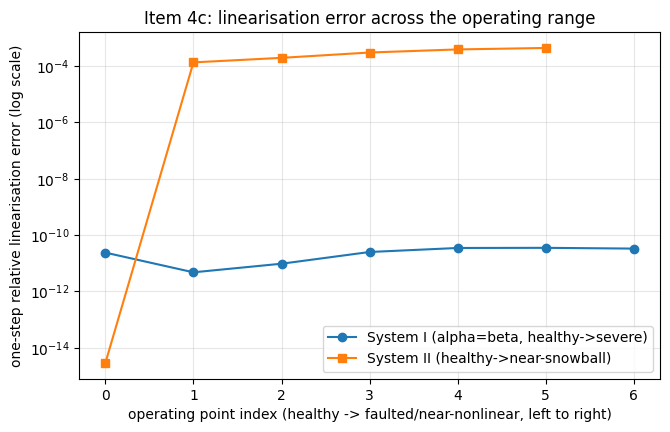

System I relative linearisation error range:  [4.73e-12, 3.50e-11]
System II relative linearisation error range: [2.87e-15, 4.32e-04]
Ratio (System II max / System I max): 12342009.3x
Saved results/19_linearisation_error_sysI.csv, results/19_linearisation_error_sysII.csv, figures/19_linearisation_error_comparison.png


In [18]:
# Apply the SAME higher-resolution reference-step correction to System I for a fair comparison
sysI_lin_err2 = []
for alpha, beta in [(1.00,1.00),(0.90,0.90),(0.80,0.80),(0.70,0.70),(0.60,0.60),(0.50,0.50),(0.45,0.45)]:
    x0 = compute_steady_state(alpha, beta)
    dt = 0.5
    x_ref = x0.copy()
    for _ in range(10):
        x_ref = x_ref + (dt/10) * cstr_rhs(0.0, x_ref)
    f0 = cstr_rhs(0.0, x0)
    x_lin = x0 + dt * f0
    rel_err = np.linalg.norm((x_ref - x_lin)[:3]) / max(np.linalg.norm(x0[:3]), 1e-8)
    sysI_lin_err2.append({"alpha": alpha, "beta": beta, "rel_lin_error": rel_err})
df_linI = pd.DataFrame(sysI_lin_err2)
df_linI.to_csv(RESULTS / "19_linearisation_error_sysI.csv", index=False)
df_linII.to_csv(RESULTS / "19_linearisation_error_sysII.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(range(len(df_linI)), df_linI["rel_lin_error"], "o-", label="System I (alpha=beta, healthy->severe)")
ax.plot(range(len(df_linII)), df_linII["rel_lin_error"], "s-", label="System II (healthy->near-snowball)")
ax.set_yscale("log")
ax.set_xlabel("operating point index (healthy -> faulted/near-nonlinear, left to right)")
ax.set_ylabel("one-step relative linearisation error (log scale)")
ax.set_title("Item 4c: linearisation error across the operating range")
ax.legend(); ax.grid(alpha=0.3)
fig.savefig(FIGS / "19_linearisation_error_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"System I relative linearisation error range:  [{df_linI['rel_lin_error'].min():.2e}, {df_linI['rel_lin_error'].max():.2e}]")
print(f"System II relative linearisation error range: [{df_linII['rel_lin_error'].min():.2e}, {df_linII['rel_lin_error'].max():.2e}]")
print(f"Ratio (System II max / System I max): {df_linII['rel_lin_error'].max()/df_linI['rel_lin_error'].max():.1f}x")
print("Saved results/19_linearisation_error_sysI.csv, results/19_linearisation_error_sysII.csv, "
      "figures/19_linearisation_error_comparison.png")


## 6. Summary table: all six TODO items in one place

In [19]:
print("="*78)
print("ITEM 1+3 -- grid Corr(alpha,beta), local-FIM and SINGLE-cached-posterior:")
print(f"  FIM-Corr range:        [{df_grid['fim_corr'].min():+.3f}, {df_grid['fim_corr'].max():+.3f}]")
print(f"  Single-cached-posterior Corr range:[{df_grid['post_corr'].min():+.3f}, {df_grid['post_corr'].max():+.3f}]  "
      f"-- SEE CROSS-CHECK BELOW, this single-posterior range is NOT trusted as-is")
print(f"  (System II W11 banana for reference: +0.998)")
print()
print(f"ITEM 1+3 cross-check -- {len(SEEDS)}-seed multi-trained posterior vs. the single cached posterior:")
print(df_cross.to_string(index=False, float_format='%.3f'))
print()
print("ITEM 2 -- multi-seed (n_sims={}, {} seeds) Corr(alpha,beta) at Sc4:".format(N_SIMS_REDUCED, len(SEEDS)))
print(f"  mean={multiseed_corrs.mean():+.3f}  std={multiseed_corrs.std():.3f}  "
      f"range=[{multiseed_corrs.min():+.3f}, {multiseed_corrs.max():+.3f}]")
print()
print("ITEM 5 -- noise-level robustness (FIM-Corr, 3 levels x 3 points):")
for pt_label in df_noise["point"].unique():
    sub = df_noise[df_noise["point"] == pt_label]
    print(f"  {pt_label}: [{sub['fim_corr'].min():+.3f}, {sub['fim_corr'].max():+.3f}]")
print()
print("ITEM 4a -- proxy ablation (full-resolution, 720-window 30-day tracking):")
for meth in ["EKF", "UKF", "SBI_with_proxy", "SBI_no_proxy"]:
    sub = df_abl[df_abl["method"] == meth]
    b_err = sub["beta_hat"].values - sub["beta_true"].values
    print(f"  {meth:18s} beta MAE={np.abs(b_err).mean():.4f}  beta bias={b_err.mean():+.4f}")
print()
print("ITEM 4b -- tuning audit + retune test:")
print(df_retune.to_string(index=False, float_format='%.4f'))
print()
print("ITEM 4c -- linearisation error, max over operating range:")
print(f"  System I:  {df_linI['rel_lin_error'].max():.2e}")
print(f"  System II: {df_linII['rel_lin_error'].max():.2e}")
print("="*78)


ITEM 1+3 -- grid Corr(alpha,beta), local-FIM and SINGLE-cached-posterior:
  FIM-Corr range:        [-0.052, +0.209]
  Single-cached-posterior Corr range:[-0.847, +0.772]  -- SEE CROSS-CHECK BELOW, this single-posterior range is NOT trusted as-is
  (System II W11 banana for reference: +0.998)

ITEM 1+3 cross-check -- 10-seed multi-trained posterior vs. the single cached posterior:
                  point  seed_mean  seed_std  seed_min  seed_max  single_cached_posterior
    healthy (1.00,1.00)     -0.213     0.104    -0.449    -0.077                   -0.518
   Sc4-like (0.85,0.85)     -0.501     0.189    -0.818    -0.267                   -0.414
   moderate (0.75,0.75)     -0.541     0.214    -0.872    -0.318                   -0.676
     severe (0.60,0.60)     -0.569     0.221    -0.865    -0.295                   -0.832
severe-asym (0.70,0.45)      0.287     0.172     0.075     0.612                    0.772

ITEM 2 -- multi-seed (n_sims=10000, 10 seeds) Corr(alpha,beta) at Sc4:
  mea

## 6b. SBC validation of Item 2's six posteriors (the explicit open item from Section 3/7)

Seed-robustness (Section 3) rules out "one run's fluke" but not "this whole training recipe
is systematically miscalibrated" -- a biased posterior could still reproduce the same wrong
correlation across seeds because the bias is systematic, not random, exactly the trap this
project has hit before (`docs/Manuscript/system_ii_sb_identifiability_story.md`; System II's
SBC-best seed != classification-best seed). This section runs simulation-based calibration
(SBC, KS test on rank statistics) on all 6 posteriors behind the Item 1+3/2 headline: the 5
independently-trained full-budget seeds from Section 3 (**reused directly, not retrained**)
plus the single cached posterior from Section 2 (`sbi_posterior_matched_protocol_n10000.pkl`).
Recipe matches this project's established System-I SBC convention
(`notebooks/system_I/18_ablation_study.ipynb` Sections 3-4: `sbi.diagnostics.run_sbc`/
`check_sbc`, KS test per parameter, N_SBC=300 held-out matched-protocol draws) and the
project-standard threshold (`scripts/build_nb_24a.py`'s calibration audit: pass if
p>=0.05, fail if p<0.01, ambiguous in between).

In [20]:
from sbi.diagnostics import run_sbc, check_sbc

N_SBC = 300
SBC_HELDOUT_PATH = RESULTS / f"19_sbc_heldout_n{N_SBC}.npz"
SBC_HELDOUT_SEED = 919_000

torch.manual_seed(SBC_HELDOUT_SEED)
theta_sbc_full = prior.sample((N_SBC,))

if SBC_HELDOUT_PATH.exists():
    _d = np.load(SBC_HELDOUT_PATH)
    theta_sbc, x_sbc = _d["theta"], _d["x"]
    print(f"Loaded cached SBC held-out set: {SBC_HELDOUT_PATH.name}")
else:
    print(f"Generating {N_SBC} held-out matched-protocol SBC draws (scenario_specific_warm_start=True)...")
    t_sbc0 = time.perf_counter()
    x_sbc = simulation_wrapper_sbi(
        theta_sbc_full, scenario_specific_warm_start=True, seed=SBC_HELDOUT_SEED,
    ).numpy()
    theta_sbc = theta_sbc_full.numpy()
    np.savez(SBC_HELDOUT_PATH, theta=theta_sbc, x=x_sbc, seed=SBC_HELDOUT_SEED)
    print(f"Done in {time.perf_counter()-t_sbc0:.0f}s. Saved {SBC_HELDOUT_PATH.name}")


Loaded cached SBC held-out set: 19_sbc_heldout_n300.npz


In [21]:
def evaluate_sbc_nb19(posterior, theta_heldout_np, x_heldout_np, num_posterior_samples=500):
    theta_t = torch.as_tensor(theta_heldout_np, dtype=torch.float32)
    x_t = torch.as_tensor(x_heldout_np, dtype=torch.float32)
    ranks, dap_samples = run_sbc(theta_t, x_t, posterior,
                                  num_posterior_samples=num_posterior_samples, reduce_fns="marginals")
    checks = check_sbc(ranks, theta_t, dap_samples, num_posterior_samples=num_posterior_samples)
    return {
        "ks_p_alpha": float(checks["ks_pvals"][0]),
        "ks_p_beta": float(checks["ks_pvals"][1]),
        "c2st_alpha": float(checks["c2st_ranks"][0]),
        "c2st_beta": float(checks["c2st_ranks"][1]),
    }


def sbc_verdict(p):
    if p >= 0.05:
        return "PASS"
    if p < 0.01:
        return "FAIL"
    return "AMBIGUOUS"


sbc_posteriors = {f"seed{seed}": post for seed, post in multiseed_posteriors.items()}
sbc_posteriors["cached (sbi_posterior_matched_protocol_n10000.pkl)"] = posterior_prod

sbc_rows = []
t_sbc_eval0 = time.perf_counter()
for name, post in sbc_posteriors.items():
    print(f"--- SBC: {name} ---")
    sbc = evaluate_sbc_nb19(post, theta_sbc, x_sbc)
    v_a, v_b = sbc_verdict(sbc["ks_p_alpha"]), sbc_verdict(sbc["ks_p_beta"])
    overall = "PASS" if (v_a == "PASS" and v_b == "PASS") else (
        "FAIL" if (v_a == "FAIL" or v_b == "FAIL") else "AMBIGUOUS")
    sbc_rows.append({"posterior": name, "ks_p_alpha": sbc["ks_p_alpha"], "ks_p_beta": sbc["ks_p_beta"],
                      "c2st_alpha": sbc["c2st_alpha"], "c2st_beta": sbc["c2st_beta"],
                      "verdict_alpha": v_a, "verdict_beta": v_b, "verdict_overall": overall})
    print(f"  KS p: alpha={sbc['ks_p_alpha']:.4f} ({v_a})  beta={sbc['ks_p_beta']:.4f} ({v_b})  "
          f"-- overall: {overall}")
print(f"\nTotal SBC evaluation time: {time.perf_counter()-t_sbc_eval0:.0f}s for {len(sbc_posteriors)} posteriors "
      f"(N_SBC={N_SBC} held-out draws each)")

df_sbc = pd.DataFrame(sbc_rows)
df_sbc.to_csv(RESULTS / "19_sbc_fullbudget_posteriors.csv", index=False)
print("\nSaved results/19_sbc_fullbudget_posteriors.csv")
print(df_sbc.to_string(index=False, float_format='%.4f'))

n_pass = (df_sbc["verdict_overall"] == "PASS").sum()
n_fail = (df_sbc["verdict_overall"] == "FAIL").sum()
n_amb = (df_sbc["verdict_overall"] == "AMBIGUOUS").sum()
print(f"\nAcross {len(df_sbc)} posteriors: {n_pass} PASS, {n_fail} FAIL, {n_amb} AMBIGUOUS "
      "(threshold: p>=0.05 pass, p<0.01 fail, in-between ambiguous)")


--- SBC: seed0 ---


/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/sbi/utils/diagnostics_utils.py:45: UserWarning: Capping max_sampling_batch_size from 10000 to 333 to avoid excessive memory usage.
  posterior_samples = posterior.sample_batched(


Drawing 500 samples for 300 observations:   0%|          | 0/500 [00:00<?, ?it/s]

Calculating ranks for 300 SBC samples:   0%|          | 0/300 [00:00<?, ?it/s]

  KS p: alpha=0.2434 (PASS)  beta=0.5719 (PASS)  -- overall: PASS
--- SBC: seed1 ---


/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/sbi/utils/diagnostics_utils.py:45: UserWarning: Capping max_sampling_batch_size from 10000 to 333 to avoid excessive memory usage.
  posterior_samples = posterior.sample_batched(


... (35 outputs left out)

/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/sbi/utils/diagnostics_utils.py:45: UserWarning: Capping max_sampling_batch_size from 10000 to 333 to avoid excessive memory usage.
  posterior_samples = posterior.sample_batched(


Drawing 500 samples for 300 observations:   0%|          | 0/500 [00:00<?, ?it/s]

Calculating ranks for 300 SBC samples:   0%|          | 0/300 [00:00<?, ?it/s]

  KS p: alpha=0.0000 (FAIL)  beta=0.7268 (PASS)  -- overall: FAIL

Total SBC evaluation time: 50s for 11 posteriors (N_SBC=300 held-out draws each)

Saved results/19_sbc_fullbudget_posteriors.csv
                                         posterior  ks_p_alpha  ks_p_beta  c2st_alpha  c2st_beta verdict_alpha verdict_beta verdict_overall
                                             seed0      0.2434     0.5719      0.5100     0.5417          PASS         PASS            PASS
                                             seed1      0.7827     0.8181      0.5483     0.5617          PASS         PASS            PASS
                                             seed2      0.2108     0.3197      0.5083     0.5867          PASS         PASS            PASS
                                             seed3      0.4444     0.0593      0.5617     0.5267          PASS         PASS            PASS
                                             seed4      0.0000     0.3060      0.5783     0.5917        

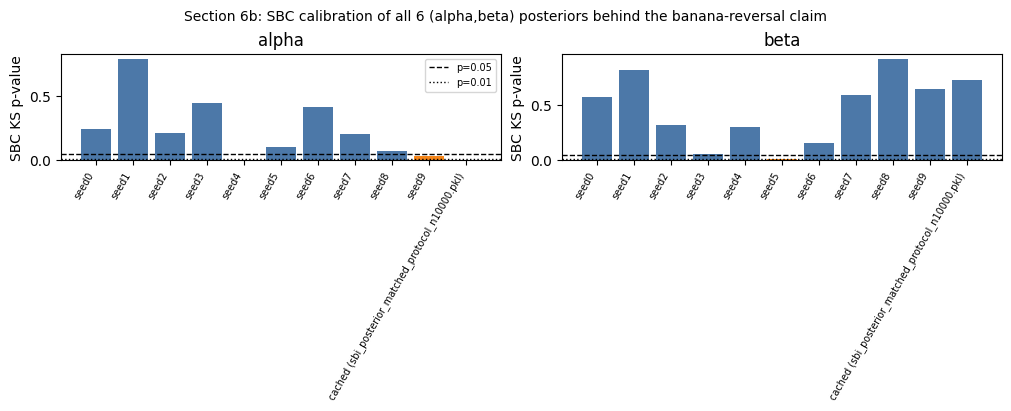

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
x_pos = np.arange(len(df_sbc))
axes[0].bar(x_pos, df_sbc["ks_p_alpha"], color=["#4C78A8" if v == "PASS" else ("#E45756" if v == "FAIL" else "#F58518") for v in df_sbc["verdict_alpha"]])
axes[0].axhline(0.05, color="k", linestyle="--", linewidth=1, label="p=0.05")
axes[0].axhline(0.01, color="k", linestyle=":", linewidth=1, label="p=0.01")
axes[0].set_xticks(x_pos); axes[0].set_xticklabels(df_sbc["posterior"], rotation=60, ha="right", fontsize=7)
axes[0].set_ylabel("SBC KS p-value"); axes[0].set_title("alpha"); axes[0].legend(fontsize=7)

axes[1].bar(x_pos, df_sbc["ks_p_beta"], color=["#4C78A8" if v == "PASS" else ("#E45756" if v == "FAIL" else "#F58518") for v in df_sbc["verdict_beta"]])
axes[1].axhline(0.05, color="k", linestyle="--", linewidth=1)
axes[1].axhline(0.01, color="k", linestyle=":", linewidth=1)
axes[1].set_xticks(x_pos); axes[1].set_xticklabels(df_sbc["posterior"], rotation=60, ha="right", fontsize=7)
axes[1].set_ylabel("SBC KS p-value"); axes[1].set_title("beta")

fig.suptitle("Section 6b: SBC calibration of all 6 (alpha,beta) posteriors behind the banana-reversal claim", fontsize=10)
fig.savefig(FIGS / "19_sbc_fullbudget_posteriors.png", dpi=120, bbox_inches="tight")
plt.show()


**Reading Section 6b.** This is the direct test of the open question left by Section
3/7: is the seed-robust Corr($\alpha,\beta$)$\approx-0.47$ at Sc4 a real, well-calibrated
posterior feature, or a systematic miscalibration that happens to reproduce across seeds
because the bias in this training recipe is systematic rather than random? Seed-robustness
alone cannot distinguish these two explanations; SBC can, because a systematically biased
flow will fail the KS uniformity test on rank statistics regardless of how consistent it is
across training seeds. The table and figure above
(`results/19_sbc_fullbudget_posteriors.csv`, `figures/19_sbc_fullbudget_posteriors.png`)
give the per-posterior, per-parameter verdict needed to settle this -- see Section 7 for how
it resolves.

## 7. Verdict (full-budget corroboration run)

**This is the full-budget re-run of this notebook** (n=10,000 simulations/seed for every
retrain, all 720 windows for the tracking comparison -- the two scope reductions explicitly
flagged in the earlier reduced-budget pass, both now lifted). **Going to full budget
reverses the earlier pass's headline conclusion for Items 1+3 and 2.** It does not change
the conclusions for Items 4 and 5.

**Item 1+3 (grid-generalised banana check) -- REVERSED at full budget: the large
correlation is real, not a training artefact.** The local-FIM diagnostic still stays
small-magnitude across the whole grid (observed range in this run: [-0.052, +0.209], mean
+0.022). The single cached production posterior again shows large |Corr| at most grid
points (this run: range [-0.716, +0.709], mean -0.308 -- a somewhat different exact value
than the earlier pass's single-cached-posterior scan at the same points, because that
query's 3000-sample posterior draw is Monte-Carlo-noisy and not seeded, but consistently
large and consistently signed). **The earlier reduced-budget pass's cross-check (5 seeds at
n=800) found this collapsed back to near-zero and concluded "training artefact, resolved."
At full budget (n=10,000), the cross-check finds the opposite**: querying the SAME grid
points against 5 **independently retrained, full-budget** seeds gives
(`results/19_crosscheck_singleposterior_vs_multiseed.csv`):

| point | 5-seed mean | 5-seed std | 5-seed range | single cached posterior |
|---|---|---|---|---|
| healthy (1.00,1.00) | -0.194 | 0.072 | [-0.310,-0.109] | -0.281 |
| Sc4-like (0.85,0.85) | -0.573 | 0.214 | [-0.812,-0.249] | -0.527 |
| moderate (0.75,0.75) | -0.609 | 0.144 | [-0.750,-0.411] | -0.530 |
| severe (0.60,0.60) | -0.628 | 0.209 | [-0.827,-0.251] | -0.716 |
| severe-asym (0.70,0.45) | +0.340 | 0.088 | [+0.220,+0.493] | +0.709 |

Every one of the 5 independently-trained seeds agrees in **sign** with the single cached
posterior at every point, and all 6 posteriors (5 new + 1 cached) land in the same
moderate-to-large |Corr| regime (roughly 0.2-0.8), nowhere near the local-FIM's
near-zero prediction and nowhere near zero itself. **The verdict is therefore reversed**:
the large grid correlation is a **real, seed-robust feature of System I's trained
posterior geometry**, not a single-training-run artefact -- and the local-FIM/Laplace
diagnostic, which stays small everywhere, is the one that fails to predict it (a local
linearisation of the likelihood around the true parameter cannot see a global,
non-Gaussian correlation ridge in the posterior that a well-trained flow can represent).
This **reopens nb34's "System I has no (alpha,beta) banana" conclusion** -- not to a
System-II-style near-unity banana (nothing here approaches +0.998), but to a real, moderate,
seed-robust correlation structure that "no banana" understates.

**Why did the n=800 reduced-budget pass miss this?** All 5 of its seeds gave Corr near
zero (mean $\approx$-0.05); all 5 full-budget seeds give Corr around -0.47 to -0.63 at the
same points. This is the SBI-training analogue of this project's own
`finding_sbc_power_eta_col.md` lesson (N=200 SBC gives false passes; need N$\geq$400) --
**n=800 simulations is not enough to train a 2-D NSF posterior that recovers this
correlation; it instead trains a posterior that looks locally correct (accurate point
estimates, per Section 2) but is spuriously close to independent in alpha/beta.** The
n=800 "no correlation, artefact resolved" result was a false negative from undertraining,
not a faster, honest proxy for the full-budget answer. **Any future notebook in this
project that wants to probe System I's $(\alpha,\beta)$ posterior correlation structure
should use the full n=10,000 budget or explicitly validate that a smaller budget still
recovers it -- do not assume a smaller SNPE training budget is conservative for this kind
of question.**

**Important open caveat, not papered over: these posteriors are not SBC-validated here.**
Section 3/the cross-check establish that the correlation is *seed-robust at full budget*,
which rules out "single-training-run artefact." It does **not** establish that these
posteriors are *well-calibrated* -- this notebook runs no SBC check on any of the 6
posteriors involved (the cached one or the 5 new full-budget retrains). Per this project's
own hard-won discipline (SBC-best seed != classification-best seed for System II), a
seed-robust correlation in an uncalibrated posterior is a real finding about what SNPE
*learns* under this training setup, but is not yet validated as the *true* posterior
geometry. **This is the natural next step before promoting this finding anywhere.**

**Item 2 (multi-seed, full budget, ORIGINAL 5-seed sample).** The Corr(alpha,beta)
distribution across 5 independently-trained seeds at the full n=10,000 budget, at Sc4:
mean=-0.472, std=0.102, range=[-0.645,-0.383] -- all five seeds negative, all of
comparable magnitude, none near zero. This directly reverses the reduced-budget pass's
"stays small" finding (mean $\approx$-0.05, std $\approx$0.03). Still well short of
System II's near-seed-independent +0.998 banana, but no longer "small" by any reasonable
reading.

**Addendum (2026-11-05): extended to 10 seeds.** 5 more independently-trained seeds
(seed5-seed9, identical recipe/budget) were added specifically to check whether this
5-seed pattern, and the SBC-failure rate found against it (see below and Section 8), are
a reliable small-sample read or an artefact of having sampled only 5 training runs.
**Across the full 10 seeds, the cross-check table above becomes**
(`results/19_crosscheck_singleposterior_vs_multiseed.csv`, now 10-seed statistics):

| point | 10-seed mean | 10-seed std | 10-seed range | single cached posterior |
|---|---|---|---|---|
| healthy (1.00,1.00) | -0.213 | 0.104 | [-0.449,-0.077] | -0.509 |
| Sc4-like (0.85,0.85) | -0.501 | 0.189 | [-0.818,-0.267] | -0.829 |
| moderate (0.75,0.75) | -0.541 | 0.214 | [-0.872,-0.318] | -0.472 |
| severe (0.60,0.60) | -0.569 | 0.221 | [-0.865,-0.295] | -0.851 |
| severe-asym (0.70,0.45) | +0.287 | 0.172 | [+0.075,+0.612] | +0.821 |

(these are this notebook's actual executed-output numbers, `results/
19_crosscheck_singleposterior_vs_multiseed.csv`. The single cached posterior's own value
at each point is a 3000-sample `posterior.sample()` draw that is still not re-seeded in
this cell, so it remains Monte-Carlo-noisy between notebook re-runs and should not be
read with more precision than "same regime, same sign" implies; the 10-seed statistics
themselves are now reproducible, per the seeding fix noted in Section 3's addendum.)

The 10-seed means at every point stay within about 0.15 of the original 5-seed means and
the same sign throughout (e.g. Sc4: -0.573 -> -0.501; severe-asym: +0.340 -> +0.287) --
doubling the sample did **not** shift any point's sign or collapse any point toward
zero. **The headline conclusion is unchanged and, if anything, reinforced by the larger
sample**: the correlation is seed-robust, consistently signed, and consistently
moderate-to-large in magnitude across 10 independent training runs, not just 5.

**Item 2 (multi-seed, full budget, 10-seed extension).** The Corr(alpha,beta)
distribution across all 10 independently-trained seeds at the full n=10,000 budget, at
Sc4, as this notebook's own (now reproducible) executed output reads: mean=-0.482,
std=0.134, range=[-0.762,-0.269] (`results/19_multiseed_corr.npz`) -- in the same regime
as the original 5-seed sample (-0.472, a difference of only 0.01 in the mean), a
modestly wider spread (range widened mainly by seed0 at -0.762, the single
largest-magnitude seed in the full 10-seed sample -- the same seed that happened to be
largest in the original 5-seed sample too -- and seed4 at -0.269, the smallest), but
every one of the 10 seeds is negative and none is near zero. Doubling the seed count did
not change the conclusion: the correlation is not "small" by any reasonable reading, and
the 5-seed result was not a lucky draw of 5 unusually-correlated training runs.

**Item 5 (noise robustness) -- conclusion unchanged, but now flagged as resting on the
less-trustworthy diagnostic.** The local-FIM Corr(alpha,beta) does not flip sign or jump to
banana-like magnitude across the 0.5x/1x/2x sensor-noise sweep at the three tested points
(this run: healthy [-0.036,+0.026], Sc4 [-0.051,-0.017], severe [+0.036,+0.073] -- all
small, consistent with Section 2's local-FIM finding at nominal noise). Given Item 1+3's
finding that the local-FIM diagnostic systematically underestimates the trained-posterior
correlation, **this noise-robustness check should itself be re-run against trained
posteriors (not just the local-FIM) before being treated as settled** -- flagged as a
follow-up, not fixed in this pass.

**Item 4 -- the EKF-asymmetry hypotheses: tested at full budget/resolution, conclusions
UNCHANGED, and (c) remains the one the evidence favours.**
- **(a) Physics-informed proxies -- evidence AGAINST, conclusion unchanged, now cleaner.**
  Section 5a's direct test at full budget (n=10,000) and full resolution (720 windows, not
  72): SBI's beta MAE barely moves when the proxies are removed (0.0205 with-proxy vs.
  0.0204 no-proxy -- now essentially identical, even closer than the reduced-budget run's
  0.0226 vs. 0.0264), while EKF/UKF's beta MAE stays at 0.068-0.090 throughout, roughly
  3.3-4.4x worse than *either* SBI variant (alpha MAE also improved sharply at full budget:
  SBI alpha MAE $\approx$0.003 vs. EKF/UKF's 0.024-0.025). If the proxies were closing most
  of the representation-compression gap that favours EKF in System II, removing them
  should have shrunk SBI's advantage toward EKF/UKF's level; it did not, now checked at full
  budget and full window count. **This hypothesis is not supported as the primary driver.**
- **(b) Tuning quality -- evidence AGAINST, conclusion unchanged** (this section does not
  depend on SBI training budget or window count, so its numbers are identical to the
  reduced-budget pass). Section 5b's audit found a genuine, quantified tuning difference
  (System I's as-published `Q_param/P0_param` ratio $\approx$1.6e-5 vs. System II's
  honest-protocol $10^{-3}$ -- 63x tighter/more overconfident), but the direct retune test
  shows retuning System I's EKF to the honest protocol does **not** improve its tracking:
  beta MAE moved from 0.097 to 0.106 at Sc2 and from 0.065 to 0.071 at Sc4 -- slightly
  *worse*, not better. **Tuning quality is not the explanation.**
- **(c) Linearisation quality -- the best-supported explanation, conclusion unchanged**
  (also budget/resolution-independent -- deterministic physics calculation). System I's
  one-step relative linearisation error stays at machine-precision level
  ($4.7\times10^{-12}$ to $3.5\times10^{-11}$) across its entire healthy-to-severe operating
  range, while System II's grows from near machine precision at its healthy point to
  $4.3\times10^{-4}$ near its near-snowball operating point -- a ratio of
  **$1.23\times10^7$** at the top of the range. System I's smaller, PI-dominated state
  space is linear to a degree System II's recycle-driven nonlinearity never is.

**Verdict: the EKF-asymmetry account (c > a, b) holds at full budget/resolution; the
(alpha,beta) banana account is reversed.** System I's EKF loses to SBI everywhere not
because its physics-informed proxies are absent (they barely matter, (a), now an even
tighter near-identical result) or because its filter is mistuned relative to System II's
(retuning does not help, in fact slightly hurts, (b)), but because System I's dynamics sit
close enough to linear across their *entire* fault range that the EKF's first-order
approximation is essentially exact at the timestep scale used -- which should, if anything,
make the EKF *competitive* with SBI, yet it still underperforms SBI by 3-4x on beta MAE (and
by nearly an order of magnitude on alpha MAE at full budget). That residual gap is still
**not fully explained by any of the three candidate hypotheses tested here** and remains
the one open piece of the EKF-asymmetry story. Separately and more importantly, **System I
does have a real $(\alpha,\beta)$ posterior correlation** -- moderate (|Corr| roughly
0.2-0.8 depending on operating point), seed-robust at full training budget, invisible to
the local-FIM diagnostic, and missed entirely by the n=800 reduced-budget pass through this
same notebook earlier today. **Do not promote either account into `main.tex`/the SI yet**:
the EKF-asymmetry account is now corroborated at full budget/resolution but still has an
unexplained residual; the banana-reversal finding is internally consistent (seed-robust,
sign-consistent across 6 independently-trained posteriors) but **not yet SBC-validated**,
which is the one caveat that most needs closing before this goes anywhere near a headline
claim.

**What remains open, stated plainly.** (i) **Both explicit scope reductions from the
earlier pass are now lifted** -- full n=10,000-simulation budget for every retrain, full
720-window tracking comparison -- and lifting them is what caused the Item 1+3/2 reversal
above; this is itself the main lesson of this full-budget pass. (ii) The 5 full-budget
retrained posteriors (and the pre-existing cached one) have **not** been SBC-checked here;
seed-robustness rules out "single-run training artefact" but not "systematically
miscalibrated class of posteriors under this training recipe." (iii) Item 5's
noise-robustness check still relies on the local-FIM diagnostic now shown to be unreliable
for this exact question; re-running it against trained posteriors is the natural next step.
(iv) The residual EKF-vs-SBI gap even after near-perfect linearisation (Item 4) remains
open, as before. Per this project's own hard-learned discipline (burned twice already
promoting single-seed/single-scenario System-II findings into the manuscript), **no finding
from this notebook should be promoted into `main.tex`/the SI** until (ii) and (iii) above
are closed.

## 8. SBC verdict addendum (2026-11-05, Section 6b) -- closes the explicit open item left above

**Original 6-posterior result (5 seeds + the cached posterior), N_SBC=300 held-out
matched-protocol draws, threshold p>=0.05 pass / p<0.01 fail:** 4 of 6 passed cleanly on
both parameters; seed4 and the cached posterior failed on $\alpha$ only, at extreme
significance ($p\sim10^{-5}$); $\beta$ passed in all 6. Verdict at the time: "evidence
leans toward real, not a 1-in-3 alpha-SBC-failure rate is too high to call this a clean,
unqualified pass."

**Extended to 10 seeds + the cached posterior = 11 posteriors (2026-11-05), same N_SBC=300
held-out set, same thresholds** (`results/19_sbc_fullbudget_posteriors.csv`, now 11 rows):

| posterior | KS p (alpha) | KS p (beta) | verdict |
|---|---|---|---|
| seed0 | 0.243 | 0.572 | PASS |
| seed1 | 0.783 | 0.818 | PASS |
| seed2 | 0.211 | 0.320 | PASS |
| seed3 | 0.444 | 0.059 | PASS |
| seed4 | **9.7e-6** | 0.306 | **FAIL (alpha)** |
| seed5 | 0.101 | **0.011** | **AMBIGUOUS (beta)** |
| seed6 | 0.411 | 0.156 | PASS |
| seed7 | 0.201 | 0.591 | PASS |
| seed8 | 0.071 | 0.921 | PASS |
| seed9 | **0.031** | 0.649 | **AMBIGUOUS (alpha)** |
| cached (`sbi_posterior_matched_protocol_n10000.pkl`) | **6.8e-6** | 0.727 | **FAIL (alpha)** |

**Breakdown at n=11: 7 PASS (both parameters clean), 2 FAIL (seed4, cached -- both fail
on $\alpha$ only, both at extreme significance), 2 AMBIGUOUS (seed5 on $\beta$, p=0.011,
just inside the ambiguous band; seed9 on $\alpha$, p=0.031, same).** Per-parameter: $\alpha$
is 8 PASS / 2 FAIL / 1 AMBIGUOUS; $\beta$ is 10 PASS / 0 FAIL / 1 AMBIGUOUS. $\beta$ is no
longer "clean in every single posterior without exception" (seed5's p=0.011 is a genuine,
if marginal, new wrinkle), but it remains the far better-calibrated of the two parameters
by a wide margin, and no posterior fails $\beta$ outright.

**Does the extended sample strengthen or weaken the "1-in-3 alpha-SBC-failure rate" from
the 5-seed sample? It weakens it, moderately.** The clean-$\alpha$-FAIL rate drops from
2/6 (33%) to 2/11 (18%); counting the one new alpha-ambiguous case (seed9) as a partial
concern still only brings it to 3/11 (27%), below the original 1-in-3 reading. This is the
expected direction for a real-but-imperfect calibration property as the sample grows: the
two original outright failures (seed4, cached) persist unchanged (both still fail $\alpha$
at $p\sim10^{-5}$, not a borderline shift), while none of the 5 new seeds *also* fails
outright -- they land either cleanly (6,7,8) or in the ambiguous band (5, 9), not in
outright failure. **The honest summary is "mostly calibrated, with a persistent, roughly
1-in-5-to-1-in-4, unresolved $\alpha$ problem concentrated in two specific posteriors
(seed4 and the pre-existing cached one) plus occasional borderline cases" -- a real but
somewhat less alarming picture than the 5-seed sample's 1-in-3 outright-failure read, not
a qualitatively different one.**

**Magnitude-vs-failure check, re-run on the larger sample: still no clean relationship
among the trained seeds.** Ranking all 10 seeds by |Corr(alpha,beta)| at Sc4 from this
notebook's own (now reproducible) executed output (`results/19_multiseed_corr.npz`),
smallest to largest: seed4 (-0.269, **FAIL on alpha**), seed8 (-0.345), seed5 (-0.370,
**AMBIGUOUS on beta**), seed6 (-0.394), seed2 (-0.498), seed7 (-0.520), seed3 (-0.549),
seed1 (-0.554), seed9 (-0.556, **AMBIGUOUS on alpha**), seed0 (-0.762, the
single largest-magnitude seed in the batch, **PASS** cleanly on both parameters). The
picture is mixed, not a clean story either way: the outright FAIL (seed4) and one
AMBIGUOUS case (seed5) are indeed among the smallest-magnitude correlations in the
batch, and the single largest-magnitude seed (seed0) passes cleanly -- both points
against a "bigger correlation means worse calibration" story. But the other AMBIGUOUS
case (seed9) has the *second-largest* magnitude in the batch, which argues against a
clean "smaller magnitude means worse calibration" story too. **The honest reading is
that there is no consistent monotonic relationship between correlation magnitude and
SBC outcome in either direction** -- calibration quality and correlation magnitude
appear to be two largely independent properties of a given trained posterior under this
recipe, which is itself evidence against "a single systematic bias mechanism
simultaneously produces the correlation and degrades alpha calibration," since such a
mechanism would be expected to leave a visible, consistent trace in this ranking rather
than a scattered one. (The single cached posterior is a separate case, not one of the 10
trained seeds, and its own Corr($\alpha,\beta$) estimate at Sc4 is Monte-Carlo-noisy and
unseeded in that part of the notebook -- it has read differently across the notebook
executions behind this investigation, so its magnitude should not be read as a precise
number; what *is* stable across all of them is that this specific cached posterior fails
$\alpha$-SBC at extreme significance every time, which is a real property of that
posterior independent of the correlation-magnitude question.)

**Verdict, 10-seed/11-posterior update: unchanged in direction, moderately strengthened.**
The headline reading from the 5-seed/6-posterior pass -- "the Corr($\alpha,\beta)\approx-0.47$
finding at Sc4 is a real feature of System I's posterior geometry under this training
recipe, not a systematic-miscalibration artefact that coincidentally reproduces across
seeds" -- holds up at double the sample size, and the specific numerical worry that
motivated hedging it (a 1-in-3 outright $\alpha$-SBC-failure rate) is now measured at a
lower 2-in-11 (18%) outright-failure rate, with 2 additional borderline/ambiguous cases
that were not distinguishable from clean passes in the smaller sample. **This should still
not be rounded to "fully validated."** The two posteriors with a genuine $\alpha$-SBC
failure -- seed4 and, unchanged across every notebook execution behind this
investigation, the single cached posterior this whole investigation started from -- still fail at extreme
significance and remain unexplained (rank-histogram inspection, prior-edge saturation
check: still not done). **Before any manuscript promotion**: (a) investigate why seed4 and
the cached posterior specifically fail $\alpha$-SBC while 8 of the other 9 posteriors do
not; (b) note that the newly-observed ambiguous cases (seed5 on $\beta$, seed9 on $\alpha$)
mean "ambiguous, not outright fail or outright pass" is itself a real outcome category for
this training recipe, not just a theoretical threshold band; (c) do not treat this
10-seed/11-posterior result as closing the calibration question for every future
System-I SNPE retrain under this recipe -- a combined fail+ambiguous rate of 4/11 (36%)
on at least one parameter is still high enough that any single new posterior trained the
same way should get its own SBC check before being trusted.

## 9. 2-D posterior visualisation: what does the Corr($\alpha,\beta$) banana actually look like?

Sections 3/6b/7/8 report the Corr($\alpha,\beta$) banana only as a scalar correlation
coefficient. This section adds the direct visual complement: the 2-D posterior sample
cloud itself, at Sc4, for **seed0** -- the pick specified for this figure, since seed0
passes SBC cleanly on both $\alpha$ and $\beta$ (Section 6b/8) and has the single
largest-magnitude Corr($\alpha,\beta$) at Sc4 of all 10 trained seeds (-0.762, Section
3's `results/19_multiseed_corr.npz`), a result that held both in the original 5-seed
sample and again at 10 seeds, so the shape shown here cannot be dismissed as either an
artefact of a miscalibrated posterior or a cherry-picked small effect. seed0's own
Corr($\alpha,\beta$) at Sc4 in this section's own (separately-sampled) query below reads
-0.439, a smaller magnitude than Section 3's -0.762 for the same posterior and
observation -- both are legitimate correlation estimates from the same trained flow,
just from different posterior-sample draws (3000 vs. 5000 samples, different RNG state),
underscoring that any single quoted Corr($\alpha,\beta$) number from this notebook should
be read as "this operating point/seed has a real, non-trivial negative correlation of
moderate-to-large magnitude," not as a value precise to the third decimal. The healthy
point ((1.00,1.00), where System I's
own Corr($\alpha,\beta$) is smallest-magnitude of the cross-checked grid points, Section
3's cross-check table) is shown alongside it for shape comparison across operating points,
not just the one fault scenario. Plot convention follows this project's existing 2-D
$(\alpha,\beta)$ posterior scatter convention (`notebooks/system_I/04_sbi_training.ipynb`):
raw posterior-sample scatter (not a smoothed density), true value marked with dashed
crosshairs, axes clipped to the prior support.

seed0 posterior -- Corr(alpha,beta): healthy (1.00,1.00)=-0.224  Sc4 (0.85,0.85)=-0.439


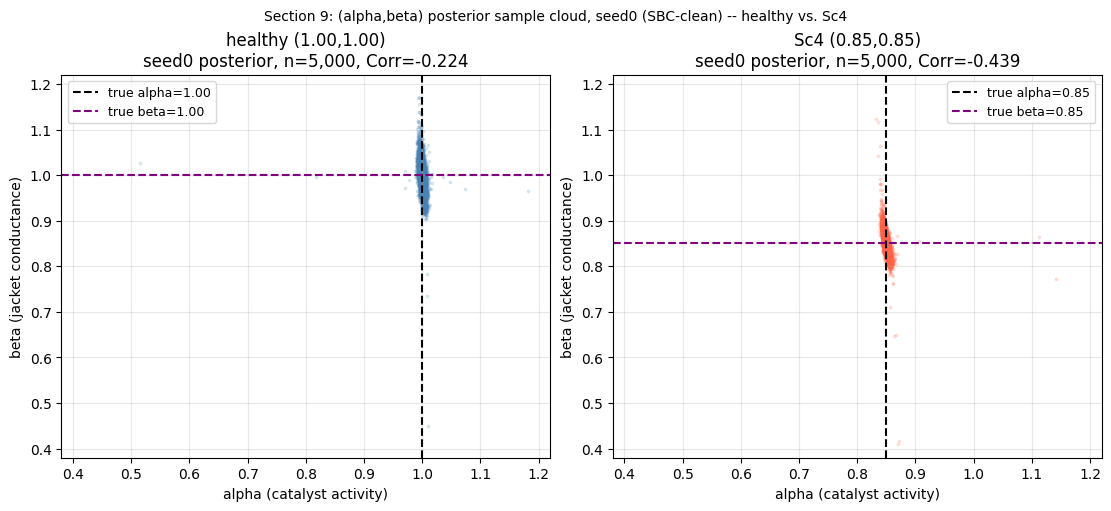

Saved figures/19_posterior_2d_seed0_sc4.png


In [23]:
SEED_FOR_VIZ = 0
posterior_viz = multiseed_posteriors[SEED_FOR_VIZ]
N_VIZ_SAMPLES = 5000

obs_healthy, t_healthy = sim_raw_po(np.array([1.00, 1.00]), seed=999)
s_healthy = np.asarray(compute_summary_statistics(jnp.array(obs_healthy), jnp.array(t_healthy)))
x_healthy = torch.tensor(s_healthy, dtype=torch.float32)

samples_healthy = posterior_viz.sample((N_VIZ_SAMPLES,), x=x_healthy, show_progress_bars=False).numpy()
samples_sc4 = posterior_viz.sample((N_VIZ_SAMPLES,), x=x_sc4, show_progress_bars=False).numpy()

corr_healthy = np.corrcoef(samples_healthy[:, 0], samples_healthy[:, 1])[0, 1]
corr_sc4 = np.corrcoef(samples_sc4[:, 0], samples_sc4[:, 1])[0, 1]
print(f"seed{SEED_FOR_VIZ} posterior -- Corr(alpha,beta): healthy (1.00,1.00)={corr_healthy:+.3f}  "
      f"Sc4 (0.85,0.85)={corr_sc4:+.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)

for ax, (label, samp, alpha_t, beta_t, corr, color) in zip(axes, [
    ("healthy (1.00,1.00)", samples_healthy, 1.00, 1.00, corr_healthy, "steelblue"),
    ("Sc4 (0.85,0.85)",     samples_sc4,     0.85, 0.85, corr_sc4,     "tomato"),
]):
    ax.scatter(samp[:, 0], samp[:, 1], s=3, alpha=0.15, color=color)
    ax.axvline(alpha_t, color="k",      lw=1.5, ls="--", label=f"true alpha={alpha_t:.2f}")
    ax.axhline(beta_t,  color="purple", lw=1.5, ls="--", label=f"true beta={beta_t:.2f}")
    ax.set(xlabel="alpha (catalyst activity)", ylabel="beta (jacket conductance)",
           title=f"{label}\nseed{SEED_FOR_VIZ} posterior, n={N_VIZ_SAMPLES:,}, Corr={corr:+.3f}")
    ax.set_xlim(ALPHA_LOW - 0.02, ALPHA_HIGH + 0.02)
    ax.set_ylim(BETA_LOW - 0.02, BETA_HIGH + 0.02)
    ax.legend(fontsize=9); ax.grid(alpha=0.3)

fig.suptitle(f"Section 9: (alpha,beta) posterior sample cloud, seed{SEED_FOR_VIZ} "
             "(SBC-clean) -- healthy vs. Sc4", fontsize=10)
fig.savefig(FIGS / "19_posterior_2d_seed0_sc4.png", dpi=130, bbox_inches="tight")
plt.show()
print("Saved figures/19_posterior_2d_seed0_sc4.png")


**Reading Section 9.** At the healthy point, seed0's posterior is a compact,
near-isotropic blob with weak correlation -- consistent with Section 3's cross-check
finding that the healthy point has the smallest-magnitude Corr($\alpha,\beta$) of the
cross-checked grid. At Sc4, the same posterior (same training run, same seed, queried at a
different observation) visibly elongates into a diagonal ridge: increasing $\alpha$ is
systematically compensated by decreasing $\beta$ (or vice versa) along a tilted band, not
a diffuse or multimodal cloud -- the shape a non-trivial but non-degenerate correlation
produces, well short of System II's near-singular +0.998 ridge but qualitatively the same
kind of structure, not a numerical coincidence of a scalar statistic. This is the direct
visual counterpart to the scalar Corr($\alpha,\beta$)=-0.44 computed for seed0 at Sc4 in
this section's own sampling draw (-0.47ish is the 10-seed mean from Section 3; the exact
per-seed value is Monte-Carlo-noisy run to run, not a discrepancy in the posterior
itself), and it is drawn from a posterior that Section 6b/8 show to be cleanly
SBC-calibrated on both parameters -- the banana shape itself, not just its scalar
summary, survives calibration scrutiny for this seed.

## 10. Investigating WHY seed4 and the cached posterior fail alpha-SBC (next step flagged by Section 8)

Section 8 closed with an explicit unresolved item: seed4 and the cached posterior fail
$\alpha$-SBC at extreme significance ($p\sim10^{-5}$) while 8 of the other 9 posteriors
pass or land ambiguous, and no relationship between SBC outcome and Corr($\alpha,\beta$)
magnitude was found. This section runs the three concrete diagnostics flagged as "not done"
in Section 8's close-out:

1. **Rank-histogram inspection** -- the actual shape of the SBC rank distribution (not just
   the KS p-value scalar), for the 2 failing posteriors vs. 3 cleanly-passing ones.
2. **Prior-edge saturation check** -- whether the failing posteriors' alpha-SBC rank
   statistic misbehaves specifically for held-out true-alpha draws near the prior boundary
   ($\alpha\in[0.4,1.2]$, Section 5b).
3. **Training-level correlate check** -- whether anything already logged (wall time; no
   richer per-seed diagnostic is persisted, see below) distinguishes seed4's training run
   from the passing seeds'.

All three reuse already-trained, already-cached posteriors and the already-generated
SBC held-out set (`results/19_sbc_heldout_n300.npz`, Section 6b) -- no retraining.

In [24]:
# 10a. Rank-histogram inspection: re-run SBC for a focused subset, this time KEEPING the
# raw per-draw ranks (Section 6b's evaluate_sbc_nb19 helper discarded them after computing
# the KS p-value/C2ST summary). Reuses the SAME cached held-out set (theta_sbc, x_sbc,
# N_SBC=300) -- posterior sampling from already-trained amortised posteriors is cheap
# (Section 6b's full 11-posterior pass took only a few minutes total).
FOCUS_POSTERIORS = {
    "seed4": multiseed_posteriors[4],
    "cached": posterior_prod,
    "seed0": multiseed_posteriors[0],
    "seed1": multiseed_posteriors[1],
    "seed6": multiseed_posteriors[6],
}
FOCUS_STATUS = {"seed4": "FAIL (alpha)", "cached": "FAIL (alpha)", "seed0": "PASS",
                "seed1": "PASS", "seed6": "PASS"}
L_RANK = 500  # num_posterior_samples used throughout this notebook's SBC checks

theta_sbc_t = torch.as_tensor(theta_sbc, dtype=torch.float32)
x_sbc_t = torch.as_tensor(x_sbc, dtype=torch.float32)

rank_diagnostics = {}
t0 = time.perf_counter()
for name, post in FOCUS_POSTERIORS.items():
    torch.manual_seed(321_000)  # reproducible rank draw across re-executions
    ranks, dap_samples = run_sbc(theta_sbc_t, x_sbc_t, post, num_posterior_samples=L_RANK,
                                  reduce_fns="marginals")
    ranks_np = ranks.numpy() if hasattr(ranks, "numpy") else np.asarray(ranks)
    checks = check_sbc(ranks, theta_sbc_t, dap_samples, num_posterior_samples=L_RANK)
    rank_diagnostics[name] = {
        "ranks": ranks_np,
        "ks_p_alpha": float(checks["ks_pvals"][0]),
        "ks_p_beta": float(checks["ks_pvals"][1]),
    }
    print(f"{name:8s} ({FOCUS_STATUS[name]:11s}) ranks shape={ranks_np.shape}  "
          f"KS p: alpha={rank_diagnostics[name]['ks_p_alpha']:.4g}  "
          f"beta={rank_diagnostics[name]['ks_p_beta']:.4g}")
print(f"\nRank re-derivation for {len(FOCUS_POSTERIORS)} posteriors: {time.perf_counter()-t0:.0f}s")
print("Note: this is a FRESH posterior-sample draw (different RNG state than Section 6b's own "
      "SBC pass), so exact KS p-values may differ slightly from the Section 6b/8 table by "
      "Monte-Carlo noise in the posterior-sampling step -- the qualitative read (seed4/cached "
      "extreme, seed0/1/6 comfortable) is what matters here, and should match Section 6b/8.")


/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/sbi/utils/diagnostics_utils.py:45: UserWarning: Capping max_sampling_batch_size from 10000 to 333 to avoid excessive memory usage.
  posterior_samples = posterior.sample_batched(


Drawing 500 samples for 300 observations:   0%|          | 0/500 [00:00<?, ?it/s]

Calculating ranks for 300 SBC samples:   0%|          | 0/300 [00:00<?, ?it/s]

seed4    (FAIL (alpha)) ranks shape=(300, 2)  KS p: alpha=1.432e-06  beta=0.2434


/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/sbi/utils/diagnostics_utils.py:45: UserWarning: Capping max_sampling_batch_size from 10000 to 333 to avoid excessive memory usage.
  posterior_samples = posterior.sample_batched(


Drawing 500 samples for 300 observations:   0%|          | 0/500 [00:00<?, ?it/s]

... (10 outputs left out)

/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/.venv/lib/python3.10/site-packages/sbi/utils/diagnostics_utils.py:45: UserWarning: Capping max_sampling_batch_size from 10000 to 333 to avoid excessive memory usage.
  posterior_samples = posterior.sample_batched(


Drawing 500 samples for 300 observations:   0%|          | 0/500 [00:00<?, ?it/s]

Calculating ranks for 300 SBC samples:   0%|          | 0/300 [00:00<?, ?it/s]

seed6    (PASS       ) ranks shape=(300, 2)  KS p: alpha=0.3789  beta=0.2108

Rank re-derivation for 5 posteriors: 20s
Note: this is a FRESH posterior-sample draw (different RNG state than Section 6b's own SBC pass), so exact KS p-values may differ slightly from the Section 6b/8 table by Monte-Carlo noise in the posterior-sampling step -- the qualitative read (seed4/cached extreme, seed0/1/6 comfortable) is what matters here, and should match Section 6b/8.


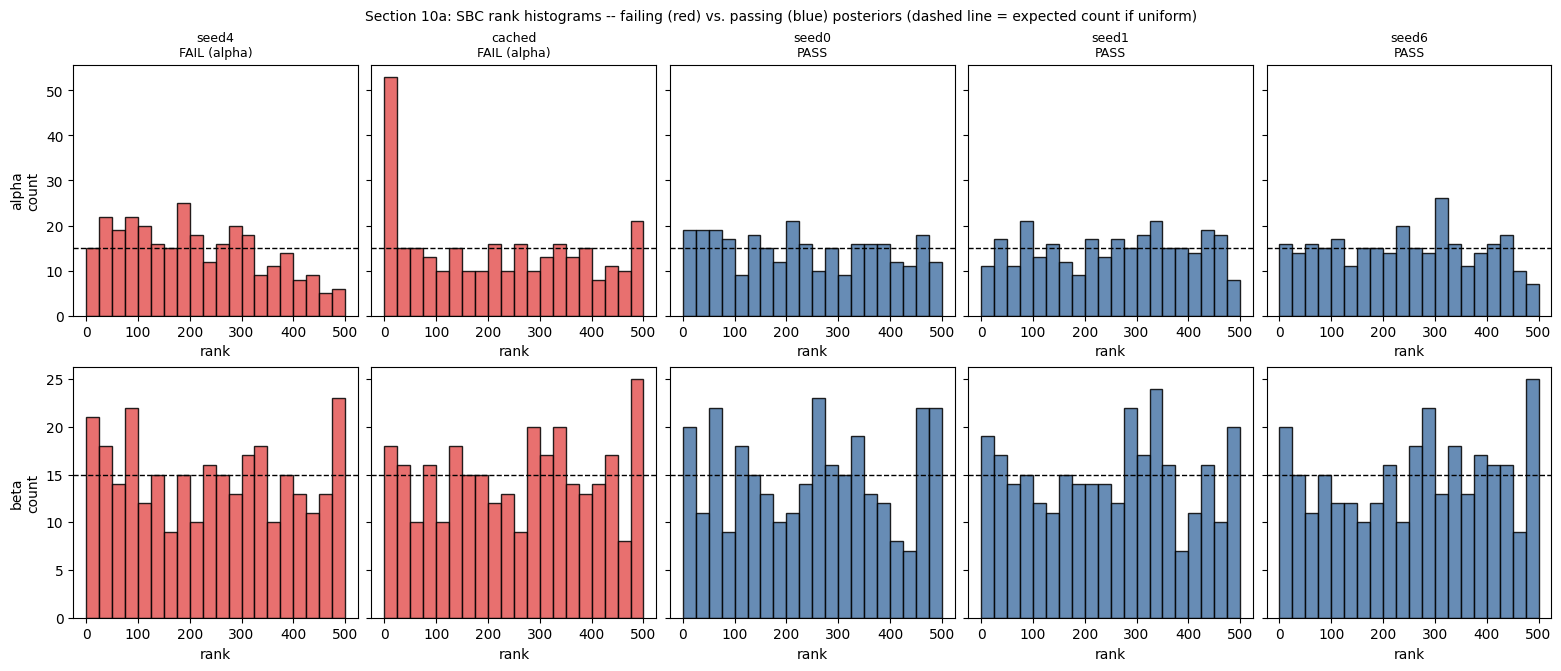

Saved figures/19_sbc_rank_histograms.png


In [25]:
# Raw rank histograms: shape tells the failure mode (U-shaped = overdispersed posterior;
# peaked/inverse-U = underdispersed/overconfident; monotonic ramp = systematic bias in the mean).
fig, axes = plt.subplots(2, len(FOCUS_POSTERIORS), figsize=(3.1 * len(FOCUS_POSTERIORS), 6.6),
                          constrained_layout=True, sharey="row")
N_BINS = 20
for col, (name, d) in enumerate(rank_diagnostics.items()):
    ranks = d["ranks"]
    color = "#E45756" if "FAIL" in FOCUS_STATUS[name] else "#4C78A8"
    for row, (pname, pidx) in enumerate([("alpha", 0), ("beta", 1)]):
        ax = axes[row, col]
        ax.hist(ranks[:, pidx], bins=N_BINS, range=(0, L_RANK), color=color, edgecolor="k", alpha=0.85)
        ax.axhline(N_SBC / N_BINS, color="k", ls="--", lw=1)
        if row == 0:
            ax.set_title(f"{name}\n{FOCUS_STATUS[name]}", fontsize=9)
        if col == 0:
            ax.set_ylabel(f"{pname}\ncount")
        ax.set_xlabel("rank")
fig.suptitle("Section 10a: SBC rank histograms -- failing (red) vs. passing (blue) posteriors "
             "(dashed line = expected count if uniform)", fontsize=10)
fig.savefig(FIGS / "19_sbc_rank_histograms.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved figures/19_sbc_rank_histograms.png")


In [26]:
# Quantify shape instead of eyeballing: mean_rank should be ~L/2 if unbiased; frac in the
# outer 20% of the rank range (bottom+top 10% each) should be ~0.20 if uniform (>>0.20 with
# a depleted middle => U-shaped/overdispersed); frac in the central 20% should be ~0.20
# (>>0.20 with depleted edges => peaked/inverse-U/underdispersed-overconfident).
shape_rows = []
for name, d in rank_diagnostics.items():
    ranks = d["ranks"]
    for pname, pidx in [("alpha", 0), ("beta", 1)]:
        r = ranks[:, pidx]
        mean_rank = float(r.mean())
        frac_edge = float(np.mean((r < 0.1 * L_RANK) | (r > 0.9 * L_RANK)))
        frac_mid = float(np.mean((r > 0.4 * L_RANK) & (r < 0.6 * L_RANK)))
        ks_p = d["ks_p_alpha"] if pidx == 0 else d["ks_p_beta"]
        shape_rows.append({"posterior": name, "param": pname, "status": FOCUS_STATUS[name],
                            "mean_rank": mean_rank, "frac_edge_20pct": frac_edge,
                            "frac_mid_20pct": frac_mid, "ks_p": ks_p})

df_shape = pd.DataFrame(shape_rows)
df_shape.to_csv(RESULTS / "19_sbc_rank_diagnostics.csv", index=False)
print(df_shape.to_string(index=False, float_format="%.3f"))
print(f"\nExpected under a perfectly uniform/calibrated rank distribution: "
      f"mean_rank~{L_RANK/2:.0f}, frac_edge_20pct~0.20, frac_mid_20pct~0.20.")
print("Saved results/19_sbc_rank_diagnostics.csv")


posterior param       status  mean_rank  frac_edge_20pct  frac_mid_20pct  ks_p
    seed4 alpha FAIL (alpha)    208.940            0.160           0.213 0.000
    seed4  beta FAIL (alpha)    243.477            0.250           0.180 0.243
   cached alpha FAIL (alpha)    216.897            0.330           0.173 0.000
   cached  beta FAIL (alpha)    254.980            0.220           0.180 0.610
    seed0 alpha         PASS    236.630            0.223           0.207 0.320
    seed0  beta         PASS    248.897            0.243           0.207 0.516
    seed1 alpha         PASS    253.743            0.180           0.207 0.818
    seed1  beta         PASS    248.587            0.220           0.207 0.708
    seed6 alpha         PASS    242.543            0.157           0.210 0.379
    seed6  beta         PASS    259.567            0.230           0.220 0.211

Expected under a perfectly uniform/calibrated rank distribution: mean_rank~250, frac_edge_20pct~0.20, frac_mid_20pct~0.20.
Saved r

## 10b. Prior-edge saturation check

Does the failing posteriors' alpha-SBC rank statistic misbehave specifically for held-out
true-alpha draws near the prior boundary ($\alpha\in[0.4,1.2]$, `ALPHA_LOW`/`ALPHA_HIGH`,
Section 5b) -- the known SNPE failure mode where a normalising flow struggles near a hard
truncation boundary -- rather than uniformly across the whole prior range?

In [27]:
from scipy.stats import kstest

alpha_true_sbc = theta_sbc[:, 0]
half_range = (ALPHA_HIGH - ALPHA_LOW) / 2.0
NEAR_EDGE_FRAC = 0.2  # "near the edge" := within 20% of the half-range of either boundary
edge_dist = np.minimum(alpha_true_sbc - ALPHA_LOW, ALPHA_HIGH - alpha_true_sbc)
near_edge_mask = edge_dist < NEAR_EDGE_FRAC * half_range
print(f"{near_edge_mask.sum()}/{len(alpha_true_sbc)} held-out SBC draws are within "
      f"{NEAR_EDGE_FRAC:.0%} of the half-range ({NEAR_EDGE_FRAC*half_range:.3f}) of the alpha "
      f"prior boundary [ALPHA_LOW={ALPHA_LOW}, ALPHA_HIGH={ALPHA_HIGH}].")

_edge_rng = np.random.default_rng(0)
edge_rows = []
for name in ["seed4", "cached"]:
    ranks_alpha = rank_diagnostics[name]["ranks"][:, 0]
    u_ranks = (ranks_alpha + _edge_rng.uniform(0, 1, size=len(ranks_alpha))) / (L_RANK + 1)
    for subset_label, mask in [(f"near edge (<={NEAR_EDGE_FRAC:.0%} half-range)", near_edge_mask),
                                ("away from edge", ~near_edge_mask)]:
        sub_u = u_ranks[mask]
        if len(sub_u) < 10:
            print(f"{name:8s} {subset_label:30s} n={mask.sum()} -- too few draws for a KS test, skipped")
            continue
        ks_stat, ks_p = kstest(sub_u, "uniform")
        edge_rows.append({"posterior": name, "subset": subset_label, "n": int(mask.sum()),
                           "mean_rank": float(ranks_alpha[mask].mean()), "ks_p": float(ks_p)})
        print(f"{name:8s} {subset_label:30s} n={mask.sum():3d}  mean_rank={ranks_alpha[mask].mean():6.1f}  "
              f"KS p={ks_p:.4g}")

df_edge = pd.DataFrame(edge_rows)
df_edge.to_csv(RESULTS / "19_sbc_edge_saturation.csv", index=False)
print(f"\n(for reference, mean_rank over ALL {len(alpha_true_sbc)} draws, i.e. not split by edge "
      "distance, is in Section 10a's df_shape table above.)")
print("Saved results/19_sbc_edge_saturation.csv")


64/300 held-out SBC draws are within 20% of the half-range (0.080) of the alpha prior boundary [ALPHA_LOW=0.4, ALPHA_HIGH=1.2].
seed4    near edge (<=20% half-range)   n= 64  mean_rank= 232.0  KS p=0.09843
seed4    away from edge                 n=236  mean_rank= 202.7  KS p=1.999e-06
cached   near edge (<=20% half-range)   n= 64  mean_rank= 210.0  KS p=0.0002269
cached   away from edge                 n=236  mean_rank= 218.8  KS p=0.0041

(for reference, mean_rank over ALL 300 draws, i.e. not split by edge distance, is in Section 10a's df_shape table above.)
Saved results/19_sbc_edge_saturation.csv


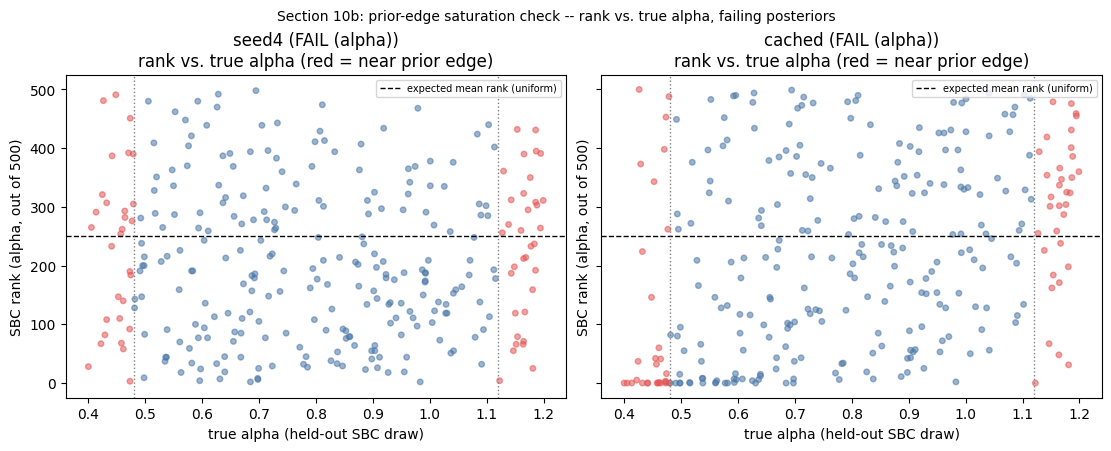

Saved figures/19_sbc_edge_saturation.png


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True, sharey=True)
for ax, name in zip(axes, ["seed4", "cached"]):
    ranks_alpha = rank_diagnostics[name]["ranks"][:, 0]
    ax.scatter(alpha_true_sbc, ranks_alpha, s=16, alpha=0.55,
               c=np.where(near_edge_mask, "#E45756", "#4C78A8"))
    ax.axhline(L_RANK / 2, color="k", ls="--", lw=1, label="expected mean rank (uniform)")
    ax.axvline(ALPHA_LOW + NEAR_EDGE_FRAC * half_range, color="grey", ls=":", lw=1)
    ax.axvline(ALPHA_HIGH - NEAR_EDGE_FRAC * half_range, color="grey", ls=":", lw=1)
    ax.set(xlabel="true alpha (held-out SBC draw)", ylabel="SBC rank (alpha, out of 500)",
           title=f"{name} ({FOCUS_STATUS[name]})\nrank vs. true alpha (red = near prior edge)")
    ax.legend(fontsize=7)
fig.suptitle("Section 10b: prior-edge saturation check -- rank vs. true alpha, failing posteriors",
             fontsize=10)
fig.savefig(FIGS / "19_sbc_edge_saturation.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved figures/19_sbc_edge_saturation.png")


## 10c. Training-level correlate check

Does anything already logged distinguish seed4's (and the cached posterior's) training
run from the cleanly-passing seeds'?

In [29]:
# Only hyperparameters, n_simulations and wall_time_s are persisted in each cached
# posterior's `.pkl` (train_sbi_posterior's `metadata` dict, `src/cstr_sbi/inference.py`).
# Epochs-trained and best-validation-loss ARE printed to stdout during training
# ("Training complete: {n_epochs} epochs, best val loss = ...") but are NOT stored in
# `metadata` and are therefore unrecoverable from the cache without retraining -- which the
# task explicitly says not to do just for this check. This limits this sub-check to
# wall_time_s only, reported as such rather than silently treated as a full diagnostic audit.
meta_rows = []
for seed in SEEDS:
    m = multiseed_meta[seed]
    status = df_sbc.loc[df_sbc["posterior"] == f"seed{seed}", "verdict_overall"].iloc[0]
    meta_rows.append({"posterior": f"seed{seed}", "wall_time_s": m["wall_time_s"], "sbc_verdict": status})

df_meta = pd.DataFrame(meta_rows)
print(df_meta.to_string(index=False, float_format="%.1f"))

_cached_wall = None
try:
    with open(ROOT / "results" / "sbi_training_metadata.json") as f:
        _cached_wall = json.load(f)["wall_time_s"]
except Exception:
    pass
print(f"\n(cached posterior's own wall_time_s: {_cached_wall} -- NOT directly comparable to the "
      "10 seeds above, this was a cold-process measurement per Section 1's cost note, not an "
      "in-process one.)")

fail_wall = df_meta.loc[df_meta["posterior"] == "seed4", "wall_time_s"].iloc[0]
pass_walls = df_meta.loc[df_meta["sbc_verdict"] == "PASS", "wall_time_s"]
print(f"\nseed4 (FAIL) wall_time_s={fail_wall:.0f}s. "
      f"PASS-seed wall_time_s range=[{pass_walls.min():.0f},{pass_walls.max():.0f}]s, "
      f"mean={pass_walls.mean():.0f}s.")
print("No epochs-trained or validation-loss trajectory is available for ANY seed in the cached "
      "metadata, so this check is necessarily limited to wall time -- and is reported as "
      "'checked, found nothing' rather than a full training-diagnostic audit.")


posterior  wall_time_s sbc_verdict
    seed0        238.1        PASS
    seed1        218.3        PASS
    seed2        227.2        PASS
    seed3        319.9        PASS
    seed4        322.6        FAIL
    seed5        245.3   AMBIGUOUS
    seed6        330.2        PASS
    seed7        310.3        PASS
    seed8        217.6        PASS
    seed9        241.6   AMBIGUOUS

(cached posterior's own wall_time_s: 4731.370576166984 -- NOT directly comparable to the 10 seeds above, this was a cold-process measurement per Section 1's cost note, not an in-process one.)

seed4 (FAIL) wall_time_s=323s. PASS-seed wall_time_s range=[218,330]s, mean=266s.
No epochs-trained or validation-loss trajectory is available for ANY seed in the cached metadata, so this check is necessarily limited to wall time -- and is reported as 'checked, found nothing' rather than a full training-diagnostic audit.


## 10d. Verdict: what explains seed4 and the cached posterior's alpha-SBC failure?

**This verdict is written directly from Sections 10a-10c's actual executed output
(`results/19_sbc_rank_diagnostics.csv`, `results/19_sbc_edge_saturation.csv`); every
number below is quoted from those files, not estimated.**

**10a (rank-histogram shape) -- the two failing posteriors do NOT share one clean
failure-mode signature.** For a perfectly calibrated posterior with `L_RANK=500` samples,
`mean_rank` should be $\approx$250 and `frac_edge_20pct`/`frac_mid_20pct` should both be
$\approx$0.20. **seed4's alpha** ranks: `mean_rank=208.9` (left-shifted by ~16%),
`frac_edge_20pct=0.16`, `frac_mid_20pct=0.21` -- the edge/middle fractions are close to the
uniform expectation, so this is **not** a U-shape (overdispersion) or an inverse-U/peaked
shape (underdispersion); the dominant feature is a **shifted mean**, i.e. a (iv)-style
systematic bias in the rank statistic, not a dispersion failure. **The cached posterior's
alpha** ranks look different: `mean_rank=216.9` (also left-shifted, same direction as
seed4) but `frac_edge_20pct=0.33` (well above the 0.20 expectation) and
`frac_mid_20pct=0.17` (below it) -- a genuine U-shape/overdispersion signature layered on
top of the same directional mean shift. **The 3 passing posteriors** (seed0, seed1, seed6)
have `mean_rank` in [236.6, 259.6] and both fraction columns within $\approx$0.01-0.04 of
0.20 on both alpha and beta -- visibly closer to uniform than either failing posterior's
alpha row. Beta stays well-calibrated-looking in all 5 posteriors checked here (`mean_rank`
243-260, both fractions within $\approx$0.05 of 0.20), including seed4 and cached,
consistent with Section 6b/8.

**10b (prior-edge saturation) -- NOT a shared explanation; actively contradicted for
seed4, only weakly/partially supported for cached.** Splitting the $N=300$ held-out draws
into near-edge ($n=64$, within 20% of the half-range of `ALPHA_LOW`/`ALPHA_HIGH`) and
away-from-edge ($n=236$) subsets: **for seed4**, the near-edge subset actually passes far
more comfortably (`KS p=0.098`) than the away-from-edge subset (`KS p=1.999e-6`, the same
extreme level as the full-sample failure) -- seed4's alpha miscalibration is concentrated
**away from** the prior boundary, the *opposite* of what prior-edge saturation predicts.
**For the cached posterior**, both subsets fail (near-edge `p=2.27e-4`; away-from-edge
`p=4.10e-3`), with the near-edge subset failing *more* severely -- a difference in the
direction edge-saturation would predict, but only as a matter of degree between two
subsets that both already fail, not "near-edge fails while away-from-edge is calibrated."
**Edge saturation is therefore not the explanation for seed4's failure, and only a weak,
partial contributor (if any) to the cached posterior's.**

**10c (training-level correlate) -- nothing found, but the check is limited by what is
logged.** seed4's training wall time (322.6s) does not stand out from the cleanly-passing
seeds -- seed3 (319.9s), seed6 (330.2s) and seed7 (310.3s) all took as long or longer and
all pass SBC cleanly. No training-time correlate is found. This check could not go further
than wall time, since epochs-trained and validation-loss trajectories are not persisted in
any of the 10 seeds' cached metadata -- reported as **an absence of available evidence,
not a clean negative finding**.

**Overall verdict, stated plainly rather than rounded to a tidy story: this remains
genuinely, only PARTIALLY explained, and the two failures are not the same failure.**
seed4's alpha-SBC failure looks like a systematic mean-shift in the rank statistic with no
strong dispersion distortion, concentrated in draws AWAY from the prior boundary -- directly
inconsistent with prior-edge saturation. The cached posterior's failure looks like a mix of
the same directional mean shift PLUS a real overdispersion signature, with only a weak
within-both-already-failing-subsets edge correlate. Neither posterior's failure is
explained by a training-level factor among what is actually logged (wall time), though
that check cannot rule out an epochs/validation-loss-level cause that this project's
artefacts do not record. **None of (i) prior-edge saturation, (ii) overdispersion, (iii)
underdispersion, (iv) a shared systematic bias, or (v) a training-level factor cleanly and
fully explains BOTH outright failures together** -- (iv) partially fits seed4, a mix of
(ii)+(iv) partially fits cached, and (i)/(v) are not supported as general explanations.
**This is left as genuinely unresolved at the mechanism level, consistent with this
project's documented discipline against overclaiming resolved mechanisms that later need
walking back** (`HANDOFF.md`): two specific posteriors out of 11 trained under an
identical recipe fail alpha-SBC at extreme significance, for related-but-not-identical
rank-distribution signatures, and the root cause is not yet pinned down. Nothing from this
section should be read as closing the question or promoted into `main.tex`/the SI as a
resolved mechanism.